# Three Body Capture of PBHs

This tutorial introduces the pipeline for three body capture simualtions figures used in the paper.  


In [1]:
%load_ext autoreload
%autoreload 2
import numpy as np
from scipy.optimize import brentq
import matplotlib.pyplot as plt
from astropy import constants as const
from astropy import units as u
from captus.three_body_capture.simulations.rebound import OrbitalSimulation
from numpy.random import SeedSequence, Generator, PCG64
import captus.utils.calculations as calc
import multiprocessing
import datetime
import captus.three_body_capture.simulations.population as pop
import captus.three_body_capture.simulations.threebodycapture as tbc
import captus.three_body_capture.simulations.threebodyevolution as tbe
import captus.utils.misc as misc
import captus.three_body_capture.plotting as pl
import os
import pandas as pd
import seaborn as sns
from astropy.cosmology import FlatLambdaCDM
from pathlib import Path



### PBH Population Generation
Here, we generate the PBH population we will run simulations on. For statistical accuracy, about 1000 PBHs are preferred per node on the mass grid constructed between given min and max mPBH values for a given number n.

In [2]:
pbh_pop_a = pop.PBHPopulation(
    system_name="Sun_Jupiter", 
    mPBH_min=1e-8 * const.M_sun.value,
    mPBH_max=1e-2 * const.M_sun.value,
    mPBH_num=7,
    n_per_mPBH=1000,
    seed_start = 0,
    identifier = "M4R4C3",
    limit_max_v=True
)

pbh_pop_b = pop.PBHPopulation(
    system_name="Sun_Jupiter", 
    mPBH_min=1e-8 * const.M_sun.value,
    mPBH_max=1e-2 * const.M_sun.value,
    mPBH_num=7,
    n_per_mPBH=1000,
    seed_start = 10,
    identifier = "M4R4C3",
    limit_max_v=True
)
# Beta Pictoris System
pbh_pop_c = pop.PBHPopulation(
    system_name="BetaPictoris",
    mPBH_min=1e-8 * const.M_sun.value,
    mPBH_max=1e-1 * const.M_sun.value,
    mPBH_num=8,
    n_per_mPBH=200,
    seed_start = 0,
    identifier = "M4R4C3",
    limit_max_v=True
)

Updated system parameter 'mC' to 1.988409870698057e+22 and recalculated rC.
Updated v_inf_grid_params 'max_v' to 30373.502689578207 and regenerated v_inf_grid.
System Parameters:
  mA: 1.988409870698051e+30
  mB: 1.8981245973360505e+27
  mC: 1.988409870698057e+22
  aB: 777908927640.0
  rB: 71492000.0
  rA: 696265000.0
  vB: 13060.0
  eB: 0.0489
  iB: 0.02275909344600606
  epsilon: 0.1
  epsilon_adjust_coeff: 0.1
  name: Sun_Jupiter_s0_Mpbh1e-08_M4R4C3
  seed_base: 0
  rC: 2.9532500761002588e-05

Simulation Parameters:
  trials: 10000000
  max_trials: 10000000000
  max_execution_time: 3600
  sample_size: 1000
  max_e: 1.0
  vDM: 220000.0
  tau_max: 10000000
  v_inf_grid_params: {'min_v': 1000, 'max_v': np.float64(30373.502689578207), 'n_v': 10}
  importance_sampling: True
  v_inf_grid: [ 1000.          4263.72252106  7527.44504213 10791.16756319
 14054.89008426 17318.61260532 20582.33512639 23846.05764745
 27109.78016851 30373.50268958]
Prepared configuration for mPBH = 1.00000000000000

#### Create non conservative copies
Here, we create copies of the populations above to inspect non-conservative (systems with 'time_exceeded' flag are included in right censored data during survival analysis) results for Neq and its derivations.

In [3]:
pbh_pop_a_nonc = pop.PBHPopulation(
    system_name="Sun_Jupiter",
    mPBH_min=1e-8 * const.M_sun.value,
    mPBH_max=1e-2 * const.M_sun.value,
    mPBH_num=7,
    n_per_mPBH=1000,
    seed_start = 0,
    identifier = "M4R4C3",
    limit_max_v=True
)
pbh_pop_b_nonc = pop.PBHPopulation(
    system_name="Sun_Jupiter", 
    mPBH_min=1e-8 * const.M_sun.value,
    mPBH_max=1e-2 * const.M_sun.value,
    mPBH_num=7,
    n_per_mPBH=1000,
    seed_start = 10,
    identifier = "M4R4C3",
    limit_max_v=True
)
pbh_pop_c_nonc = pop.PBHPopulation(
    system_name="BetaPictoris",
    mPBH_min=1e-8 * const.M_sun.value,
    mPBH_max=1e-1 * const.M_sun.value,
    mPBH_num=8,
    n_per_mPBH=200,
    seed_start = 0,
    identifier = "M4R4C3",
    limit_max_v=True
)

Updated system parameter 'mC' to 1.988409870698057e+22 and recalculated rC.
Updated v_inf_grid_params 'max_v' to 30373.502689578207 and regenerated v_inf_grid.
System Parameters:
  mA: 1.988409870698051e+30
  mB: 1.8981245973360505e+27
  mC: 1.988409870698057e+22
  aB: 777908927640.0
  rB: 71492000.0
  rA: 696265000.0
  vB: 13060.0
  eB: 0.0489
  iB: 0.02275909344600606
  epsilon: 0.1
  epsilon_adjust_coeff: 0.1
  name: Sun_Jupiter_s0_Mpbh1e-08_M4R4C3
  seed_base: 0
  rC: 2.9532500761002588e-05

Simulation Parameters:
  trials: 10000000
  max_trials: 10000000000
  max_execution_time: 3600
  sample_size: 1000
  max_e: 1.0
  vDM: 220000.0
  tau_max: 10000000
  v_inf_grid_params: {'min_v': 1000, 'max_v': np.float64(30373.502689578207), 'n_v': 10}
  importance_sampling: True
  v_inf_grid: [ 1000.          4263.72252106  7527.44504213 10791.16756319
 14054.89008426 17318.61260532 20582.33512639 23846.05764745
 27109.78016851 30373.50268958]
Prepared configuration for mPBH = 1.00000000000000

## Generating Paper Simulations
One can run following cells to reproduce the paper results.

In [ ]:
tbodycap_a = tbc.ThreeBodyCapture(pbh_pop_a.population_dict)
tbodycap_a.run_simulation(num_cores=10)

tbodycap_b = tbc.ThreeBodyCapture(pbh_pop_b.population_dict)
tbodycap_b.run_simulation(num_cores=10)

pbh_pop_a.sample_mc()
pbh_pop_b.sample_mc()

In [ ]:
tbodycap_c = tbc.ThreeBodyCapture(pbh_pop_c.population_dict)
tbodycap_c.run_simulation(num_cores=10)

pbh_pop_c.sample_mc()

CAUTION: Evolution simulations at paper scale might take a few days depending on the machine when run in 50 cores per population. The total data size will be around 3 TB.

In [ ]:
tbodyev_a = tbe.ThreeBodyEvolution(pbh_pop_a.population_dict, verbose=False)
tbodyev_a.run_simulation(num_cores=50)

tbodyev_b = tbe.ThreeBodyEvolution(pbh_pop_b.population_dict, verbose=False)
tbodyev_b.run_simulation(num_cores=50)

In [ ]:
tbodyev_c = tbe.ThreeBodyEvolution(pbh_pop_c.population_dict, verbose=False)
tbodyev_c.run_simulation(num_cores=50)

## Read and Analyse Results
Simulations were done for paper previously, therefore we can read simulation files and analyse directly.

In [ ]:
pbh_pop_a.analyze_population()
pbh_pop_b.analyze_population()

Analyzing final results for configuration: Sun_Jupiter_s0_Mpbh1e-08_M4R4C3
Loading MC results from: /data/a.saricaoglu/repo/captus/notebooks/../runs/Sun_Jupiter_s0_Mpbh1e-08_M4R4C3/Monte_Carlo_Results
Loading Rebound results from: /data/a.saricaoglu/repo/captus/notebooks/../runs/Sun_Jupiter_s0_Mpbh1e-08_M4R4C3/Rebound_Simulation_Results
Using cached results dictionary.
Analyzing final results for configuration: Sun_Jupiter_s1_Mpbh1e-07_M4R4C3
Loading MC results from: /data/a.saricaoglu/repo/captus/notebooks/../runs/Sun_Jupiter_s1_Mpbh1e-07_M4R4C3/Monte_Carlo_Results
Loading Rebound results from: /data/a.saricaoglu/repo/captus/notebooks/../runs/Sun_Jupiter_s1_Mpbh1e-07_M4R4C3/Rebound_Simulation_Results
Using cached results dictionary.
Analyzing final results for configuration: Sun_Jupiter_s2_Mpbh1e-06_M4R4C3
Loading MC results from: /data/a.saricaoglu/repo/captus/notebooks/../runs/Sun_Jupiter_s2_Mpbh1e-06_M4R4C3/Monte_Carlo_Results
Loading Rebound results from: /data/a.saricaoglu/repo/c

In [8]:
pbh_pop_c.analyze_population()

Analyzing final results for configuration: BetaPictoris_s0_Mpbh1e-08_M4R4C3
Loading MC results from: /data/a.saricaoglu/repo/captus/notebooks/../runs/BetaPictoris_s0_Mpbh1e-08_M4R4C3/Monte_Carlo_Results
Loading Rebound results from: /data/a.saricaoglu/repo/captus/notebooks/../runs/BetaPictoris_s0_Mpbh1e-08_M4R4C3/Rebound_Simulation_Results
Using cached results dictionary.
Analyzing final results for configuration: BetaPictoris_s1_Mpbh1e-07_M4R4C3
Loading MC results from: /data/a.saricaoglu/repo/captus/notebooks/../runs/BetaPictoris_s1_Mpbh1e-07_M4R4C3/Monte_Carlo_Results
Loading Rebound results from: /data/a.saricaoglu/repo/captus/notebooks/../runs/BetaPictoris_s1_Mpbh1e-07_M4R4C3/Rebound_Simulation_Results
Using cached results dictionary.
Analyzing final results for configuration: BetaPictoris_s2_Mpbh1e-06_M4R4C3
Loading MC results from: /data/a.saricaoglu/repo/captus/notebooks/../runs/BetaPictoris_s2_Mpbh1e-06_M4R4C3/Monte_Carlo_Results
Loading Rebound results from: /data/a.saricaogl

In [9]:
pbh_pop_a_nonc.analyze_population()
pbh_pop_b_nonc.analyze_population()
pbh_pop_c_nonc.analyze_population()

Analyzing final results for configuration: Sun_Jupiter_s0_Mpbh1e-08_M4R4C3
Loading MC results from: /data/a.saricaoglu/repo/captus/notebooks/../runs/Sun_Jupiter_s0_Mpbh1e-08_M4R4C3/Monte_Carlo_Results
Loading Rebound results from: /data/a.saricaoglu/repo/captus/notebooks/../runs/Sun_Jupiter_s0_Mpbh1e-08_M4R4C3/Rebound_Simulation_Results
Using cached results dictionary.
Analyzing final results for configuration: Sun_Jupiter_s1_Mpbh1e-07_M4R4C3
Loading MC results from: /data/a.saricaoglu/repo/captus/notebooks/../runs/Sun_Jupiter_s1_Mpbh1e-07_M4R4C3/Monte_Carlo_Results
Loading Rebound results from: /data/a.saricaoglu/repo/captus/notebooks/../runs/Sun_Jupiter_s1_Mpbh1e-07_M4R4C3/Rebound_Simulation_Results
Using cached results dictionary.
Analyzing final results for configuration: Sun_Jupiter_s2_Mpbh1e-06_M4R4C3
Loading MC results from: /data/a.saricaoglu/repo/captus/notebooks/../runs/Sun_Jupiter_s2_Mpbh1e-06_M4R4C3/Monte_Carlo_Results
Loading Rebound results from: /data/a.saricaoglu/repo/c

Make a list of analyses to create a table for the capture rates, number of system in equilibrium, number of system in equilibrium for total PBH fraction, and number of system in equilibrium for the PBH fraction bounded by observations; at r-8 kpc (Solar vicinity) from the galactic center.

In [24]:
pop_dict_a = pbh_pop_a.get_population_dict()
pop_dict_b = pbh_pop_b.get_population_dict()

analysis_list_a = []
analysis_list_b = []

for pop in list(pop_dict_a.values()):
    analysis_list_a.append(pop["analysis"])
    print(pop["analysis"].results_dictionary)
for pop in list(pop_dict_b.values()):
    analysis_list_b.append(pop["analysis"])

{'mA': 1.988409870698051e+30, 'mB': 1.8981245973360505e+27, 'mC': np.float64(1.988409870698057e+22), 'aB': 777908927640.0, 'rB': 71492000.0, 'rA': 696265000.0, 'vB': 13060.0, 'eB': 0.0489, 'iB': 0.02275909344600606, 'epsilon': 0.1, 'epsilon_adjust_coeff': 0.1, 'name': 'Sun_Jupiter_s0_Mpbh1e-08_M4R4C3', 'seed_base': 0, 'rC': np.float64(2.9532500761002588e-05), 'trials': 10000000, 'max_trials': 10000000000, 'max_execution_time': 3600, 'sample_size': 1000, 'max_e': 1.0, 'vDM': 220000.0, 'tau_max': 10000000, 'v_inf_grid_params': {'min_v': 1000, 'max_v': np.float64(30373.502689578207), 'n_v': 10}, 'importance_sampling': True, 'v_inf_grid': array([ 1000.        ,  4263.72252106,  7527.44504213, 10791.16756319,
       14054.89008426, 17318.61260532, 20582.33512639, 23846.05764745,
       27109.78016851, 30373.50268958]), 'V1': {'v_inf': array(1000.), 'n_captured': 1000, 'sigma_MC_m2': array(1.08056765e+21), 'sigma_MC_dsigma_au2': array(0.01567815), 'cap_a_au': array([4.53954795e+01, 1.1207323

In [53]:
betapic_analysis_list = []
for pop in list(pbh_pop_c.get_population_dict().values()):
    betapic_analysis_list.append(pop["analysis"])

In [ ]:
pop_dict_a_nonc = pbh_pop_a_nonc.get_population_dict()
pop_dict_b_nonc = pbh_pop_b_nonc.get_population_dict()

analysis_list_a_nonc = []
analysis_list_b_nonc = []

for pop in list(pop_dict_a_nonc.values()):
    analysis_list_a_nonc.append(pop["analysis"])
for pop in list(pop_dict_b_nonc.values()):
    analysis_list_b_nonc.append(pop["analysis"])



betapic_analysis_list_nonc = []
for pop in list(pbh_pop_c_nonc.get_population_dict().values()):
    betapic_analysis_list_nonc.append(pop["analysis"])  

## Table 1
Following cell generates data for the Table 1 in the paper.

In [ ]:
# Create table save path
file_path = Path(Path.cwd()).resolve()
table_save_path = file_path.parent / "tables"
table_save_path.mkdir(exist_ok=True)

for r in [0.05, 2.2, 8.0]:    
    p = misc.get_MW_params(r)
    dm_rho_local_gev_cm3 = p['DM_density'] * 1e-7 * 0.3796 / (u.M_sun/u.kpc**3)
    print(f"Local DM density: {dm_rho_local_gev_cm3} ")
    print(f"Local DM velocity: {p['v_circ']}")
    print(f"Local DM dispersion: {p['DM_dispersion']} ")

## Table 2
Following cell generates Table 2 in paper. Tables for non conservative results are also created here, although they are not included in the paper.

In [27]:
combined_analysis_list_r8 = []

for a1, a2 in zip(analysis_list_a, analysis_list_b):
    combined = a1.merged_copy_for_error_analysis(a2)
    combined.update_results_dictionary(r=8)
    combined_analysis_list_r8.append(combined)   

combined_analysis_list_r2p2 = []

for a1, a2 in zip(analysis_list_a, analysis_list_b):
    combined = a1.merged_copy_for_error_analysis(a2)
    combined.update_results_dictionary(r=2.2)
    combined_analysis_list_r2p2.append(combined) 

combined_analysis_list_r005 = []

for a1, a2 in zip(analysis_list_a, analysis_list_b):
    combined = a1.merged_copy_for_error_analysis(a2)
    combined.update_results_dictionary(r=0.05)
    combined_analysis_list_r005.append(combined) 


Using cached data in results dictionary as base for update, (MC and Rebound data not relaoded).
Using cached data in results dictionary as base for update, (MC and Rebound data not relaoded).
Using cached data in results dictionary as base for update, (MC and Rebound data not relaoded).
Using cached data in results dictionary as base for update, (MC and Rebound data not relaoded).
Using cached data in results dictionary as base for update, (MC and Rebound data not relaoded).
Using cached data in results dictionary as base for update, (MC and Rebound data not relaoded).
Using cached data in results dictionary as base for update, (MC and Rebound data not relaoded).
Using cached data in results dictionary as base for update, (MC and Rebound data not relaoded).
Using cached data in results dictionary as base for update, (MC and Rebound data not relaoded).
Using cached data in results dictionary as base for update, (MC and Rebound data not relaoded).
Using cached data in results dictionary 

In [ ]:
combined_analysis_list_r8_nonc = []

for a1, a2 in zip(analysis_list_a_nonc, analysis_list_b_nonc):
    combined = a1.merged_copy_for_error_analysis(a2)
    combined.set_conservative_results(conservative=False, update=False)
    combined.update_results_dictionary(r=8)
    combined_analysis_list_r8_nonc.append(combined)   

combined_analysis_list_r2p2_nonc = []

for a1, a2 in zip(analysis_list_a_nonc, analysis_list_b_nonc):
    combined = a1.merged_copy_for_error_analysis(a2)
    combined.set_conservative_results(conservative=False, update=False)
    combined.update_results_dictionary(r=2.2)
    combined_analysis_list_r2p2_nonc.append(combined) 

combined_analysis_list_r005_nonc = []

for a1, a2 in zip(analysis_list_a_nonc, analysis_list_b_nonc):
    combined = a1.merged_copy_for_error_analysis(a2)
    combined.set_conservative_results(conservative=False, update=False)
    combined.update_results_dictionary(r=0.05)
    combined_analysis_list_r005_nonc.append(combined) 


Using cached data in results dictionary as base for update, (MC and Rebound data not relaoded).
Using cached data in results dictionary as base for update, (MC and Rebound data not relaoded).
Using cached data in results dictionary as base for update, (MC and Rebound data not relaoded).
Using cached data in results dictionary as base for update, (MC and Rebound data not relaoded).
Using cached data in results dictionary as base for update, (MC and Rebound data not relaoded).
Using cached data in results dictionary as base for update, (MC and Rebound data not relaoded).
Using cached data in results dictionary as base for update, (MC and Rebound data not relaoded).
Using cached data in results dictionary as base for update, (MC and Rebound data not relaoded).
Using cached data in results dictionary as base for update, (MC and Rebound data not relaoded).
Using cached data in results dictionary as base for update, (MC and Rebound data not relaoded).
Using cached data in results dictionary 

In [82]:
analyses_by_r = {
    8.0: combined_analysis_list_r8,
    2.2: combined_analysis_list_r2p2,
    0.05: combined_analysis_list_r005,
}

sigma = 2
TABLE_METRICS = [
    {
        "label": r"$R_{\mathrm{cap},k}$ [Myr$^{-1}$]",
        "value_path": ("total_occurrences_gl", "capture_rate_gl"),
        "error_key": "total_cap_err",
        "scale": 1e6,
        "decimals": 2,
        "scientific": False,
    },
    {
        "label": r"$N_{\mathrm{eq},k}$ [$n_\infty$ AU$^3$]",
        "value_path": ("total_occurrences_gl", "total_systems_neq_gl"),
        "error_key": "total_neq_err",
        "scale": 1.0,
        "decimals": 2,
        "scientific": False,
    },
    {
        "label": r"$N_{\mathrm{eq},k}(f_{\mathrm{total}})$",
        "value_path": ("total_pbh_neq_n", "Neq_pbh_f_full"),
        "error_key": "full_neq_err",
        "scale": 1.0,
        "decimals": 1,
        "scientific": True,
    },
    {
        "label": r"$N_{\mathrm{eq},k}(f_{\mathrm{bound}})$",
        "value_path": ("total_pbh_neq_n", "Neq_pbh_f_bound"),
        "error_key": "bound_neq_err",
        "scale": 1.0,
        "decimals": 1,
        "scientific": True,
    },
]

table_r_sj = misc.create_r_k_table(
    analyses_by_r,
    sigma=sigma,
    selected_k=[1, 5, 6, 7],
    table_metrics=TABLE_METRICS
)
table_r_sj.insert(
    1,
    r"$\cdots$",
    r"$\cdots$",
)
latex = table_r_sj.to_latex(escape=False, multirow=True, multicolumn=True)
print(latex)

\begin{tabular}{lllllll}
\toprule
 &  & $k=1$ & $\cdots$ & $k=5$ & $k=6$ & $k=7$ \\
$r$ [kpc] & $G_k(v_\infty);\,M_{\mathrm{P},k}$ &  &  &  &  &  \\
\midrule
\multirow[t]{4}{*}{8.000000} & $R_{\mathrm{cap},k}$ [Myr$^{-1}$] & $0.27 \pm 0.01$ & $\cdots$ & $0.31 \pm 0.01$ & $0.76 \pm 0.02$ & $7.46 \pm 0.20$ \\
 & $N_{\mathrm{eq},k}$ [$n_\infty$ AU$^3$] & $0.15 \pm 0.01$ & $\cdots$ & $0.17 \pm 0.01$ & $4.17 \pm 0.14$ & $41.79 \pm 1.34$ \\
 & $N_{\mathrm{eq},k}(f_{\mathrm{total}})$ & $(2.1 \pm 0.1) \times 10^{-11}$ & $\cdots$ & $(2.4 \pm 0.1) \times 10^{-15}$ & $(5.9 \pm 0.2) \times 10^{-15}$ & $(5.9 \pm 0.2) \times 10^{-15}$ \\
 & $N_{\mathrm{eq},k}(f_{\mathrm{bound}})$ & $(2.0 \pm 0.1) \times 10^{-13}$ & $\cdots$ & $(4.5 \pm 0.2) \times 10^{-18}$ & $(1.3 \pm 0.0) \times 10^{-18}$ & $(1.5 \pm 0.0) \times 10^{-19}$ \\
\cline{1-7}
\multirow[t]{4}{*}{2.200000} & $R_{\mathrm{cap},k}$ [Myr$^{-1}$] & $0.42 \pm 0.01$ & $\cdots$ & $0.49 \pm 0.02$ & $1.19 \pm 0.03$ & $11.66 \pm 0.31$ \\
 & $N_{\mat

In [85]:
analyses_by_r_sj_nonc = {
    8.0: combined_analysis_list_r8_nonc,
    2.2: combined_analysis_list_r2p2_nonc,
    0.05: combined_analysis_list_r005_nonc,
}

table_r_sj_nonc = misc.create_r_k_table(
    analyses_by_r_sj_nonc,
    sigma=sigma,
    selected_k=[1, 5, 6, 7],
    table_metrics=TABLE_METRICS
)
table_r_sj_nonc.insert(
    1,
    r"$\cdots$",
    r"$\cdots$",
)
latex = table_r_sj_nonc.to_latex(escape=False, multirow=True, multicolumn=True)
print(latex)


\begin{tabular}{lllllll}
\toprule
 &  & $k=1$ & $\cdots$ & $k=5$ & $k=6$ & $k=7$ \\
$r$ [kpc] & $G_k(v_\infty);\,M_{\mathrm{P},k}$ &  &  &  &  &  \\
\midrule
\multirow[t]{4}{*}{8.000000} & $R_{\mathrm{cap},k}$ [Myr$^{-1}$] & $0.27 \pm 0.01$ & $\cdots$ & $0.31 \pm 0.01$ & $0.76 \pm 0.02$ & $7.46 \pm 0.20$ \\
 & $N_{\mathrm{eq},k}$ [$n_\infty$ AU$^3$] & $0.16 \pm 0.01$ & $\cdots$ & $0.18 \pm 0.01$ & $4.96 \pm 0.16$ & $56.22 \pm 1.67$ \\
 & $N_{\mathrm{eq},k}(f_{\mathrm{total}})$ & $(2.2 \pm 0.1) \times 10^{-11}$ & $\cdots$ & $(2.5 \pm 0.1) \times 10^{-15}$ & $(7.0 \pm 0.2) \times 10^{-15}$ & $(7.9 \pm 0.2) \times 10^{-15}$ \\
 & $N_{\mathrm{eq},k}(f_{\mathrm{bound}})$ & $(2.1 \pm 0.1) \times 10^{-13}$ & $\cdots$ & $(4.7 \pm 0.2) \times 10^{-18}$ & $(1.5 \pm 0.0) \times 10^{-18}$ & $(2.0 \pm 0.1) \times 10^{-19}$ \\
\cline{1-7}
\multirow[t]{4}{*}{2.200000} & $R_{\mathrm{cap},k}$ [Myr$^{-1}$] & $0.42 \pm 0.01$ & $\cdots$ & $0.49 \pm 0.02$ & $1.19 \pm 0.03$ & $11.66 \pm 0.31$ \\
 & $N_{\mat

In [ ]:
import copy
def clone_analysis_for_r(analysis, r):
    cloned = copy.copy(analysis)
    cloned.update_results_dictionary(r=r)
    return cloned

    
analysis_list_betapic_r8 = []

for a in betapic_analysis_list:
    cloned = clone_analysis_for_r(a, 8)
    # cloned.set_conservative_results(conservative=True, update=False)
    analysis_list_betapic_r8.append(cloned)


analyses_by_r_bp_r8 = {
    8.0: analysis_list_betapic_r8,
}


Using cached data in results dictionary as base for update, (MC and Rebound data not relaoded).
Using cached data in results dictionary as base for update, (MC and Rebound data not relaoded).
Using cached data in results dictionary as base for update, (MC and Rebound data not relaoded).
Using cached data in results dictionary as base for update, (MC and Rebound data not relaoded).
Using cached data in results dictionary as base for update, (MC and Rebound data not relaoded).
Using cached data in results dictionary as base for update, (MC and Rebound data not relaoded).
Using cached data in results dictionary as base for update, (MC and Rebound data not relaoded).
Using cached data in results dictionary as base for update, (MC and Rebound data not relaoded).


In [67]:

TABLE_METRICS = [
    {
        "label": r"$R_{\mathrm{cap},k}$ [Myr$^{-1}$]",
        "value_path": ("total_occurrences_gl", "capture_rate_gl"),
        "error_key": "total_cap_err",
        "scale": 1e6,
        "decimals": 0,
        "scientific": False,
    },
    {
        "label": r"$N_{\mathrm{eq},k}$ [$n_\infty$ AU$^3$]",
        "value_path": ("total_occurrences_gl", "total_systems_neq_gl"),
        "error_key": "total_neq_err",
        "scale": 1.0,
        "decimals": 0,
        "scientific": False,
    },
    {
        "label": r"$N_{\mathrm{eq},k}(f_{\mathrm{total}})$",
        "value_path": ("total_pbh_neq_n", "Neq_pbh_f_full"),
        "error_key": "full_neq_err",
        "scale": 1.0,
        "decimals": 1,
        "scientific": True,
    },
    {
        "label": r"$N_{\mathrm{eq},k}(f_{\mathrm{bound}})$",
        "value_path": ("total_pbh_neq_n", "Neq_pbh_f_bound"),
        "error_key": "bound_neq_err",
        "scale": 1.0,
        "decimals": 1,
        "scientific": True,
    },
]

r = 8
sigma = 2
table_r_bp = misc.create_r_k_table(
    analyses_by_r_bp_r8,
    sigma=sigma,
    selected_k=[1, 6, 7, 8],
    table_metrics=TABLE_METRICS
)
table_r_bp.insert(
    1,
    r"$\cdots$",
    r"$\cdots$",
)
latex = table_r_bp.to_latex(escape=False, multirow=True, multicolumn=True)
print(latex)


\begin{tabular}{lllllll}
\toprule
 &  & $k=1$ & $\cdots$ & $k=6$ & $k=7$ & $k=8$ \\
$r$ [kpc] & $G_k(v_\infty);\,M_{\mathrm{P},k}$ &  &  &  &  &  \\
\midrule
\multirow[t]{4}{*}{8.000000} & $R_{\mathrm{cap},k}$ [Myr$^{-1}$] & $13 \pm 1$ & $\cdots$ & $14 \pm 1$ & $30 \pm 3$ & $173 \pm 13$ \\
 & $N_{\mathrm{eq},k}$ [$n_\infty$ AU$^3$] & $5 \pm 1$ & $\cdots$ & $4 \pm 1$ & $122 \pm 14$ & $816 \pm 80$ \\
 & $N_{\mathrm{eq},k}(f_{\mathrm{total}})$ & $(7.5 \pm 2.1) \times 10^{-10}$ & $\cdots$ & $(5.8 \pm 1.6) \times 10^{-15}$ & $(1.7 \pm 0.2) \times 10^{-14}$ & $(1.1 \pm 0.1) \times 10^{-14}$ \\
 & $N_{\mathrm{eq},k}(f_{\mathrm{bound}})$ & $(7.3 \pm 2.0) \times 10^{-12}$ & $\cdots$ & $(1.3 \pm 0.3) \times 10^{-18}$ & $(4.3 \pm 0.5) \times 10^{-19}$ & $(3.8 \pm 0.4) \times 10^{-20}$ \\
\cline{1-7}
\bottomrule
\end{tabular}



In [ ]:
analysis_list_betapic_r8_nonc = []

for a in betapic_analysis_list_nonc:
    cloned = clone_analysis_for_r(a, 8)
    cloned.set_conservative_results(conservative=False, update=True)
    analysis_list_betapic_r8_nonc.append(cloned)

analyses_by_r_bp_r8_nonc = {
    8.0: analysis_list_betapic_r8_nonc,
}   

table_r_bp_nonc = misc.create_r_k_table(
    analyses_by_r_bp_r8_nonc,
    sigma=sigma,
    selected_k=[1, 6, 7, 8],
    table_metrics=TABLE_METRICS
)
table_r_bp_nonc.insert(
    1,
    r"$\cdots$",
    r"$\cdots$",
)
latex = table_r_bp_nonc.to_latex(escape=False, multirow=True, multicolumn=True)
print(latex)


\begin{tabular}{lllllll}
\toprule
 &  & $k=1$ & $\cdots$ & $k=6$ & $k=7$ & $k=8$ \\
$r$ [kpc] & $G_k(v_\infty);\,M_{\mathrm{P},k}$ &  &  &  &  &  \\
\midrule
\multirow[t]{4}{*}{8.000000} & $R_{\mathrm{cap},k}$ [Myr$^{-1}$] & $13 \pm 1$ & $\cdots$ & $14 \pm 1$ & $30 \pm 3$ & $173 \pm 13$ \\
 & $N_{\mathrm{eq},k}$ [$n_\infty$ AU$^3$] & $11 \pm 2$ & $\cdots$ & $11 \pm 3$ & $138 \pm 15$ & $963 \pm 89$ \\
 & $N_{\mathrm{eq},k}(f_{\mathrm{total}})$ & $(1.6 \pm 0.3) \times 10^{-9}$ & $\cdots$ & $(1.5 \pm 0.4) \times 10^{-14}$ & $(1.9 \pm 0.2) \times 10^{-14}$ & $(1.4 \pm 0.1) \times 10^{-14}$ \\
 & $N_{\mathrm{eq},k}(f_{\mathrm{bound}})$ & $(1.5 \pm 0.3) \times 10^{-11}$ & $\cdots$ & $(3.4 \pm 0.8) \times 10^{-18}$ & $(4.8 \pm 0.5) \times 10^{-19}$ & $(4.4 \pm 0.4) \times 10^{-20}$ \\
\cline{1-7}
\bottomrule
\end{tabular}



In [70]:
analysis_list_betapic_r2p2 = []

for a in betapic_analysis_list:
    cloned = clone_analysis_for_r(a, 2.2)
    analysis_list_betapic_r2p2.append(cloned)

analyses_by_r_bp_r2p2 = {
    2.2: analysis_list_betapic_r2p2,
}



Using cached data in results dictionary as base for update, (MC and Rebound data not relaoded).
Using cached data in results dictionary as base for update, (MC and Rebound data not relaoded).
Using cached data in results dictionary as base for update, (MC and Rebound data not relaoded).
Using cached data in results dictionary as base for update, (MC and Rebound data not relaoded).
Using cached data in results dictionary as base for update, (MC and Rebound data not relaoded).
Using cached data in results dictionary as base for update, (MC and Rebound data not relaoded).
Using cached data in results dictionary as base for update, (MC and Rebound data not relaoded).
Using cached data in results dictionary as base for update, (MC and Rebound data not relaoded).


In [ ]:
table_r_bp_2 = misc.create_r_k_table(
    analyses_by_r_bp_r2p2,
    sigma=sigma,
    selected_k=[1, 6, 7, 8],
    table_metrics=TABLE_METRICS
)

table_r_bp_2.insert(
    1,
    r"$\cdots$",
    r"$\cdots$",
)
latex = table_r_bp_2.to_latex(escape=False, multirow=True, multicolumn=True)
print(latex)

\begin{tabular}{lllllll}
\toprule
 &  & $k=1$ & $\cdots$ & $k=6$ & $k=7$ & $k=8$ \\
$r$ [kpc] & $G_k(v_\infty);\,M_{\mathrm{P},k}$ &  &  &  &  &  \\
\midrule
\multirow[t]{4}{*}{2.200000} & $R_{\mathrm{cap},k}$ [Myr$^{-1}$] & $20 \pm 2$ & $\cdots$ & $22 \pm 2$ & $46 \pm 4$ & $270 \pm 21$ \\
 & $N_{\mathrm{eq},k}$ [$n_\infty$ AU$^3$] & $8 \pm 2$ & $\cdots$ & $6 \pm 2$ & $191 \pm 22$ & $1275 \pm 124$ \\
 & $N_{\mathrm{eq},k}(f_{\mathrm{total}})$ & $(4.5 \pm 1.2) \times 10^{-9}$ & $\cdots$ & $(3.5 \pm 0.9) \times 10^{-14}$ & $(1.0 \pm 0.1) \times 10^{-13}$ & $(6.8 \pm 0.7) \times 10^{-14}$ \\
 & $N_{\mathrm{eq},k}(f_{\mathrm{bound}})$ & $(4.4 \pm 1.2) \times 10^{-11}$ & $\cdots$ & $(7.6 \pm 2.0) \times 10^{-18}$ & $(2.6 \pm 0.3) \times 10^{-18}$ & $(2.2 \pm 0.2) \times 10^{-19}$ \\
\cline{1-7}
\bottomrule
\end{tabular}



In [79]:
analysis_list_betapic_r2p2_nonc = []

for a in betapic_analysis_list_nonc:
    a.set_conservative_results(conservative=False, update=False)
    cloned = clone_analysis_for_r(a, 2.2)
    analysis_list_betapic_r2p2_nonc.append(cloned)

analyses_by_r_bp_r2p2_nonc = {
    2.2: analysis_list_betapic_r2p2_nonc,
}   

table_r_bp_nonc_2p2 = misc.create_r_k_table(
    analyses_by_r_bp_r2p2_nonc,
    sigma=sigma,
    selected_k=[1, 6, 7, 8],
    table_metrics=TABLE_METRICS
)
table_r_bp_nonc_2p2.insert(
    1,
    r"$\cdots$",
    r"$\cdots$",
)
latex = table_r_bp_nonc_2p2.to_latex(escape=False, multirow=True, multicolumn=True)
print(latex)


Using cached data in results dictionary as base for update, (MC and Rebound data not relaoded).
Using cached data in results dictionary as base for update, (MC and Rebound data not relaoded).
Using cached data in results dictionary as base for update, (MC and Rebound data not relaoded).
Using cached data in results dictionary as base for update, (MC and Rebound data not relaoded).
Using cached data in results dictionary as base for update, (MC and Rebound data not relaoded).
Using cached data in results dictionary as base for update, (MC and Rebound data not relaoded).
Using cached data in results dictionary as base for update, (MC and Rebound data not relaoded).
Using cached data in results dictionary as base for update, (MC and Rebound data not relaoded).
\begin{tabular}{lllllll}
\toprule
 &  & $k=1$ & $\cdots$ & $k=6$ & $k=7$ & $k=8$ \\
$r$ [kpc] & $G_k(v_\infty);\,M_{\mathrm{P},k}$ &  &  &  &  &  \\
\midrule
\multirow[t]{4}{*}{2.200000} & $R_{\mathrm{cap},k}$ [Myr$^{-1}$] & $20 \pm

In [72]:
analysis_list_betapic_r005 = [clone_analysis_for_r(pop, 0.05) for pop in betapic_analysis_list]
analyses_by_r_bp_r005 = {
    0.05: analysis_list_betapic_r005,
}

table_r_bp_005 = misc.create_r_k_table(
    analyses_by_r_bp_r005,
    sigma=sigma,
    selected_k=[1, 6, 7, 8],
    table_metrics=TABLE_METRICS
)
table_r_bp_005.insert(
    1,
    r"$\cdots$",
    r"$\cdots$",
)
latex = table_r_bp_005.to_latex(escape=False, multirow=True, multicolumn=True)
print(latex)

Using cached data in results dictionary as base for update, (MC and Rebound data not relaoded).
Using cached data in results dictionary as base for update, (MC and Rebound data not relaoded).
Using cached data in results dictionary as base for update, (MC and Rebound data not relaoded).
Using cached data in results dictionary as base for update, (MC and Rebound data not relaoded).
Using cached data in results dictionary as base for update, (MC and Rebound data not relaoded).
Using cached data in results dictionary as base for update, (MC and Rebound data not relaoded).
Using cached data in results dictionary as base for update, (MC and Rebound data not relaoded).
Using cached data in results dictionary as base for update, (MC and Rebound data not relaoded).
\begin{tabular}{lllllll}
\toprule
 &  & $k=1$ & $\cdots$ & $k=6$ & $k=7$ & $k=8$ \\
$r$ [kpc] & $G_k(v_\infty);\,M_{\mathrm{P},k}$ &  &  &  &  &  \\
\midrule
\multirow[t]{4}{*}{0.050000} & $R_{\mathrm{cap},k}$ [Myr$^{-1}$] & $350 \p

In [76]:
analysis_list_betapic_r005_nonc = []

for a in betapic_analysis_list_nonc:
    a.set_conservative_results(conservative=False, update=False)
    cloned = clone_analysis_for_r(a, 0.05)
    analysis_list_betapic_r005_nonc.append(cloned)

analyses_by_r_bp_r005_nonc = {
    0.05: analysis_list_betapic_r005_nonc,
}   

table_r_bp_nonc_005 = misc.create_r_k_table(
    analyses_by_r_bp_r005_nonc,
    sigma=sigma,
    selected_k=[1, 6, 7, 8],
    table_metrics=TABLE_METRICS
)
table_r_bp_nonc_005.insert(
    1,
    r"$\cdots$",
    r"$\cdots$",
)
latex = table_r_bp_nonc_005.to_latex(escape=False, multirow=True, multicolumn=True)
print(latex)


Using cached data in results dictionary as base for update, (MC and Rebound data not relaoded).
Using cached data in results dictionary as base for update, (MC and Rebound data not relaoded).
Using cached data in results dictionary as base for update, (MC and Rebound data not relaoded).
Using cached data in results dictionary as base for update, (MC and Rebound data not relaoded).
Using cached data in results dictionary as base for update, (MC and Rebound data not relaoded).
Using cached data in results dictionary as base for update, (MC and Rebound data not relaoded).
Using cached data in results dictionary as base for update, (MC and Rebound data not relaoded).
Using cached data in results dictionary as base for update, (MC and Rebound data not relaoded).
\begin{tabular}{lllllll}
\toprule
 &  & $k=1$ & $\cdots$ & $k=6$ & $k=7$ & $k=8$ \\
$r$ [kpc] & $G_k(v_\infty);\,M_{\mathrm{P},k}$ &  &  &  &  &  \\
\midrule
\multirow[t]{4}{*}{0.050000} & $R_{\mathrm{cap},k}$ [Myr$^{-1}$] & $350 \p

## Figure 4
This figure only represents pbh_pop_a, as declared in the paper.

In [130]:
plotobj = pl.Plots(name="Sun_Jupiter_Set_A_paper", analysis=analysis_list_a, exclude_zero_capture=True)
plotobj_bp = pl.Plots(name="Beta_Pictoris_paper", analysis=betapic_analysis_list, exclude_zero_capture=True)


Using cached results dictionary.
Using cached results dictionary.
Using cached results dictionary.
Using cached results dictionary.
Using cached results dictionary.
Using cached results dictionary.
Using cached results dictionary.
Using cached results dictionary.
Using cached results dictionary.
Using cached results dictionary.
Using cached results dictionary.
Using cached results dictionary.
Using cached results dictionary.
Using cached results dictionary.
Using cached results dictionary.


<unknown>:491: SyntaxWarning: invalid escape sequence '\o'
<unknown>:1039: SyntaxWarning: invalid escape sequence '\o'
<unknown>:1236: SyntaxWarning: invalid escape sequence '\o'
<unknown>:1486: SyntaxWarning: invalid escape sequence '\o'
<unknown>:2721: SyntaxWarning: invalid escape sequence '\%'
<unknown>:491: SyntaxWarning: invalid escape sequence '\o'
<unknown>:1039: SyntaxWarning: invalid escape sequence '\o'
<unknown>:1236: SyntaxWarning: invalid escape sequence '\o'
<unknown>:1486: SyntaxWarning: invalid escape sequence '\o'
<unknown>:2721: SyntaxWarning: invalid escape sequence '\%'


V1
✓ Found in analysis_dict
✓ Found in an_entry
✓ Found in an_entry
✓ Found in an_entry
  1315 valid points
  Reversed axes: x reversed=True, y reversed=False
  33 outliers detected
  ✓ Finished subplot
✓ Found in an_entry
✓ Found in an_entry
✓ Found in an_entry
  776 valid points
  Reversed axes: x reversed=True, y reversed=False
  29 outliers detected
  ✓ Finished subplot
✓ Found in an_entry
✓ Found in an_entry
✓ Found in an_entry
  384 valid points
  Reversed axes: x reversed=True, y reversed=False
  11 outliers detected
  ✓ Finished subplot
✓ Found in an_entry
✓ Found in an_entry
✓ Found in an_entry
  229 valid points
  Reversed axes: x reversed=True, y reversed=False
  4 outliers detected
  ✓ Finished subplot
✓ Found in an_entry
✓ Found in an_entry
✓ Found in an_entry
  192 valid points
  Reversed axes: x reversed=True, y reversed=False
  0 outliers detected
  ✓ Finished subplot
✓ Found in an_entry
✓ Found in an_entry
✓ Found in an_entry
  163 valid points
  Reversed axes: x rever

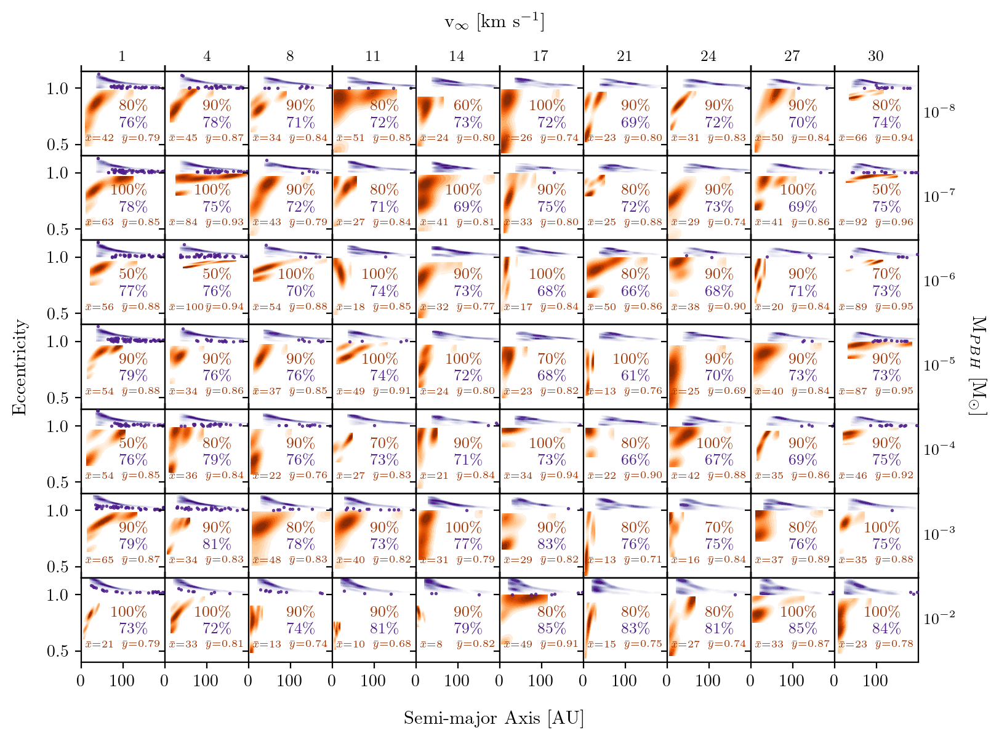

In [22]:
plotobj.multiple_analysis_metric_gaussian_kde_multipanel(
    metric_xnames=['nocap_a_au', 'cap_a_au'],
    metric_ynames=['nocap_e', 'cap_e'],
    metric_xlabel='Semi-major Axis [AU]',
    metric_ylabel='Eccentricity',
    unit_change=[1, 1, 1],
    # analysis_key=[analysis_list[0].name, analysis_list[-1].name],
    cmaps=['Purples', 'Oranges'],
    scale=['linear', 'linear', 'linear'],
    bw_adjust=0.6,  # ← Bandwidth adjustment
    thresh=0.1,      # ← Outlier threshold (10% of max)
    plot_outliers=True,  # ← Show outliers
    ranges=[(0, 200), (0.4, 1.15), None],
    ticks=[(0, 100), (0.5,1.0), None],
    save=True,
    cut=0.0,
    add_negative_top_axis=True,
    mean_annotations=True,
    reverse_axes = [[True, False], [False, False]],  # ← Reverse x-axis for row 0
    percentage_annotations=True,
    fig_size=(8, 6),
    save_as="a_e_kde_initial.png",
    # metric_mask=[None, {"type":"flag_contains", "substr" : "time_exceeded", "mask_type": "exclude"}] # ← Example: only include systems that exceeded time limit

)

## Figure 5

<>:2: SyntaxWarning: invalid escape sequence '\s'
<>:27: SyntaxWarning: invalid escape sequence '\s'
<>:2: SyntaxWarning: invalid escape sequence '\s'
<>:27: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_2436226/2489576700.py:2: SyntaxWarning: invalid escape sequence '\s'
  mlabels0 = [ '$\sigma_{cap}$']
/tmp/ipykernel_2436226/2489576700.py:27: SyntaxWarning: invalid escape sequence '\s'
  mlabels0 = [ '$\sigma_{cap}$']


✓ Found in analysis_dict
✓ Found in analysis_dict
✓ Found in occurrences
✓ Found in occurrences
✓ Found in occurrences
✓ Found in occurrences
✓ Found in occurrences
✓ Found in occurrences
✓ Found in occurrences
✓ Found in occurrences
✓ Found in occurrences
✓ Found in occurrences
✓ Found in occurrences
✓ Found in occurrences
✓ Found in occurrences
✓ Found in occurrences
✓ Found in occurrences
✓ Found in occurrences
✓ Found in occurrences
✓ Found in occurrences
✓ Found in occurrences
✓ Found in occurrences
Formatting 1.00e-08 as 1.00 × 10^-8
✓ Found in occurrences
✓ Found in occurrences
✓ Found in occurrences
✓ Found in occurrences
✓ Found in occurrences
✓ Found in occurrences
✓ Found in occurrences
✓ Found in occurrences
✓ Found in occurrences
✓ Found in occurrences
✓ Found in occurrences
✓ Found in occurrences
✓ Found in occurrences
✓ Found in occurrences
✓ Found in occurrences
✓ Found in occurrences
✓ Found in occurrences
✓ Found in occurrences
✓ Found in occurrences
✓ Found in occurr

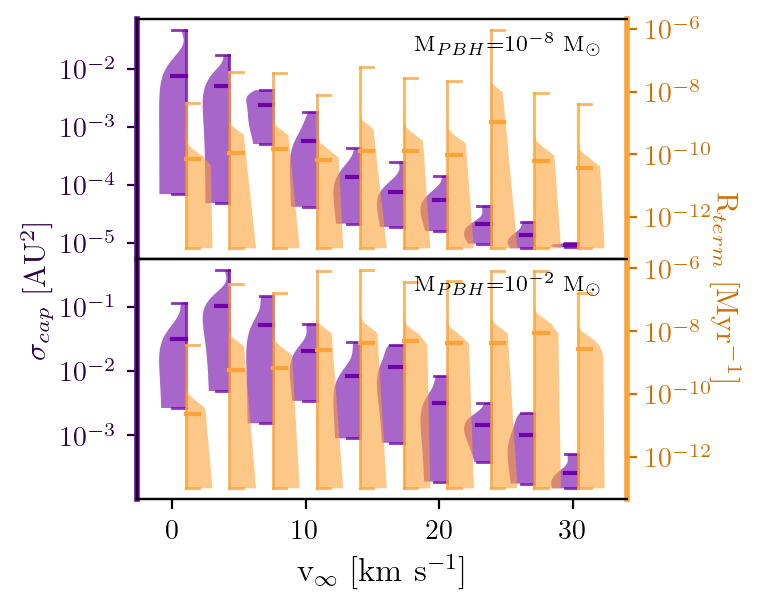

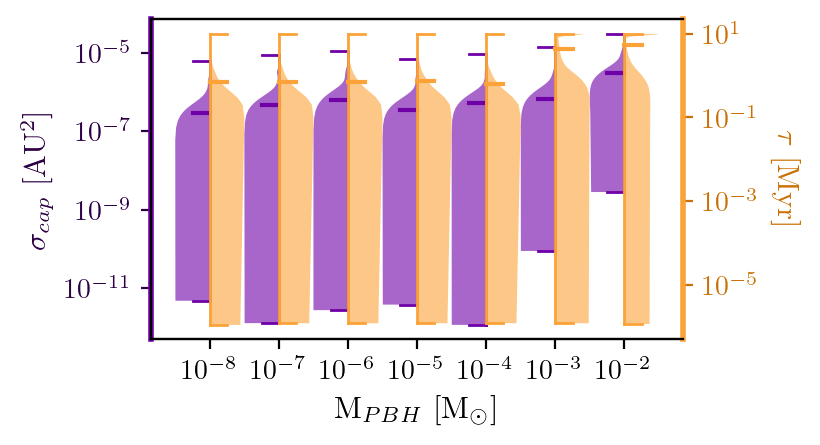

In [27]:
mlist0 = ['dsigma_au2']
mlabels0 = [ '$\sigma_{cap}$']
mylabel0 =r'$\sigma_{cap}$ [AU$^{2}$]'
mlist1 = ['terminations']

mlabels1 = [r'R$_{term}$']
mylabel1 =r'R$_{term}$ [Myr$^{-1}$]'
mlists = [mlist0, mlist1]

mlabels = [mlabels0, mlabels1]
mylabels = [mylabel0, mylabel1]

plotobj.multiple_analysis_metric_array_wrt_v_twinaxis_multipanel(
    metric_lists=mlists,
    metric_ylabels= (mylabel0, mylabel1),
    scale=['log','log'],
    analysis_key=[analysis_list_a[0].name, analysis_list_a[-1].name],
    v_key='All',
    global_ylim=False,
    unit_change=[1, 1e-6],
    fig_size=(3.5,3),
    save=True,
    save_as='capture_cross_section_vs_lifetime_first_last.png'
)

mlist0 = ['capture_cross_section_total_array']
mlabels0 = [ '$\sigma_{cap}$']
mylabel0 =r'$\sigma_{cap}$ [AU$^{2}$]'
mlist1 = ['lifetimes_array']
mlabels1 = [r'$\tau$ [Myr]']
mylabel1 =r'$\tau$ [Myr]'
mlists = [mlist0, mlist1]
mlabels = [mlabels0, mlabels1]
mylabels = [mylabel0, mylabel1]
plotobj.multiple_analysis_metric_array_wrt_m_twinaxis_violin(
    metric_lists=mlists, 
    metric_labels=mlabels,
    metric_ylabels=mylabels,
    fig_size=(3.5, 2),
    save=True,
    scale=['log', 'log', 'log'] ,#[metric1[x,y,z], metric2[x,y,z]]
    unit_change= [1/const.M_sun.value, 1, 1e-6], #[metric1[x,y,z], metric2[x,y,z]]
    # metric_masks=[[None], [{"type":"flag_contains", "substr" : "time_exceeded", "mask_type": "exclude"}]]
    save_as='capture_cross_section_vs_lifetime_combined.png'
    )

## Figure 6

✓ Found in analysis_dict
✓ Found in analysis_dict
✓ Found in analysis_dict

📊 Processing metric 1/2: semi_major_axes
✓ Found in rebound: 1000 entries
✓ Found in rebound: 1000 entries
✓ Found in rebound: 1000 entries
✓ Found in rebound: 1000 entries
✓ Found in rebound: 1000 entries
✓ Found in rebound: 1000 entries
✓ Found in rebound: 1000 entries
✓ Found in rebound: 1000 entries
✓ Found in rebound: 1000 entries
✓ Found in rebound: 1000 entries
✓ Found in rebound: 1000 entries
✓ Found in rebound: 1000 entries
✓ Found in rebound: 1000 entries
✓ Found in rebound: 1000 entries
✓ Found in rebound: 1000 entries
✓ Found in rebound: 1000 entries
✓ Found in rebound: 1000 entries
✓ Found in rebound: 1000 entries
✓ Found in rebound: 1000 entries
✓ Found in rebound: 1000 entries
✓ Found in rebound: 1000 entries
✓ Found in rebound: 1000 entries
✓ Found in rebound: 1000 entries
✓ Found in rebound: 1000 entries


/grad/a.saricaoglu/.conda/envs/captus/lib/python3.12/site-packages/numpy/_core/fromnumeric.py:3824: RuntimeWarning: Mean of empty slice
  return _methods._mean(a, axis=axis, dtype=dtype,
/grad/a.saricaoglu/.conda/envs/captus/lib/python3.12/site-packages/numpy/_core/_methods.py:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


✓ Found in rebound: 1000 entries
✓ Found in rebound: 1000 entries
✓ Found in rebound: 1000 entries
✓ Found in rebound: 1000 entries
✓ Found in rebound: 1000 entries
✓ Found in rebound: 1000 entries
✓ Found in rebound: 1000 entries
✓ Found in rebound: 1000 entries
✓ Found in rebound: 1000 entries
✓ Found in rebound: 1000 entries
✓ Found in rebound: 1000 entries
✓ Found in rebound: 1000 entries
✓ Found in rebound: 1000 entries
✓ Found in rebound: 1000 entries
✓ Found in rebound: 1000 entries
✓ Found in rebound: 1000 entries
✓ Found in rebound: 1000 entries
✓ Found in rebound: 1000 entries
✓ Found in rebound: 1000 entries
✓ Found in rebound: 1000 entries
✓ Found in rebound: 1000 entries
✓ Found in rebound: 1000 entries
✓ Found in rebound: 1000 entries
✓ Found in rebound: 1000 entries
✓ Found in rebound: 1000 entries
✓ Found in rebound: 1000 entries
✓ Found in rebound: 1000 entries
✓ Found in rebound: 1000 entries
✓ Found in rebound: 1000 entries
✓ Found in rebound: 1000 entries
✓ Found in

{}

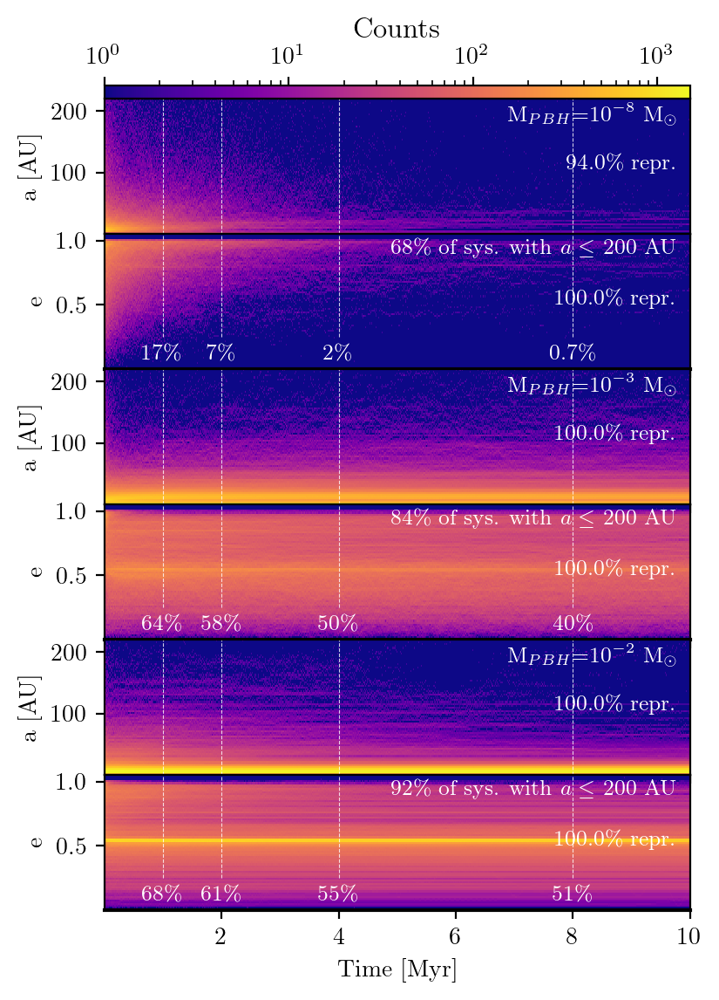

In [ ]:
a_max = 200
plotobj.multiple_analysis_time_series_2dhistogram_multipanel_stacked(
    metric_names=['semi_major_axes', 'eccentricities'],
    metric_ylabels=[r'a [AU]', r'e'],
    time_ylabel=r'Time [Myr]',
    metric_ranges=[(0, a_max+0.1*a_max), (0, 1.05)],
    ticks=[None, [a_max/2, a_max], [0.5, 1.0], None],
    scale=['linear', 'linear', 'linear', 'log'],
    survivor_per_at_t = [1e6, 2e6, 4e6, 8e6],
    analysis_key=[analysis_list[0].name, analysis_list[-2].name, analysis_list[-1].name],
    unit_change=[1e-6, 1, 1],
    dt_fixed=12,
    metric_bins=75,
    mask_labels=[rf'of sys. with $a \leq$ {a_max} AU', fr'of sys. with $a \leq$ {a_max} AU', None],
    metric_masks=[{
        "type": "where",
        "key": "semi_major_axes",  # Time series of semi-major axes
        "predicate": lambda a_arr: np.mean(a_arr) <= a_max # Average a over time
    },
        {
        "type": "where",
        "key": "semi_major_axes",  # Time series of semi-major axes
        "predicate": lambda a_arr: np.mean(a_arr) <= a_max  # Average a over time
    }], # No mask for orbital_periods
    fig_size=(4, 5),  # Tall figure for 5 analyses × 2 metrics
    save_as=f'stacked_timeseries_histograms_bothmasked_{a_max}au_first_last.png'
)

<unknown>:487: SyntaxWarning: invalid escape sequence '\o'
<unknown>:762: SyntaxWarning: invalid escape sequence '\o'
<unknown>:1997: SyntaxWarning: invalid escape sequence '\%'
<unknown>:2393: SyntaxWarning: invalid escape sequence '\%'
<unknown>:487: SyntaxWarning: invalid escape sequence '\o'
<unknown>:762: SyntaxWarning: invalid escape sequence '\o'
<unknown>:1997: SyntaxWarning: invalid escape sequence '\%'
<unknown>:2393: SyntaxWarning: invalid escape sequence '\%'


✓ Found in analysis_dict
✓ Found in analysis_dict
✓ Found in analysis_dict

📊 Processing metric 1/2: semi_major_axes
✓ Found in rebound: 1000 entries
✓ Found in rebound: 1000 entries
✓ Found in rebound: 1000 entries
✓ Found in rebound: 1000 entries
✓ Found in rebound: 1000 entries
✓ Found in rebound: 1000 entries
✓ Found in rebound: 1000 entries
✓ Found in rebound: 1000 entries
✓ Found in rebound: 1000 entries
✓ Found in rebound: 1000 entries
✓ Found in rebound: 1000 entries
✓ Found in rebound: 1000 entries
✓ Found in rebound: 1000 entries
✓ Found in rebound: 1000 entries
✓ Found in rebound: 1000 entries
✓ Found in rebound: 1000 entries
✓ Found in rebound: 1000 entries
✓ Found in rebound: 1000 entries
✓ Found in rebound: 1000 entries
✓ Found in rebound: 1000 entries
✓ Found in rebound: 1000 entries
✓ Found in rebound: 1000 entries
✓ Found in rebound: 1000 entries
✓ Found in rebound: 1000 entries
✓ Found in rebound: 1000 entries
✓ Found in rebound: 1000 entries
✓ Found in rebound: 1000 

{}

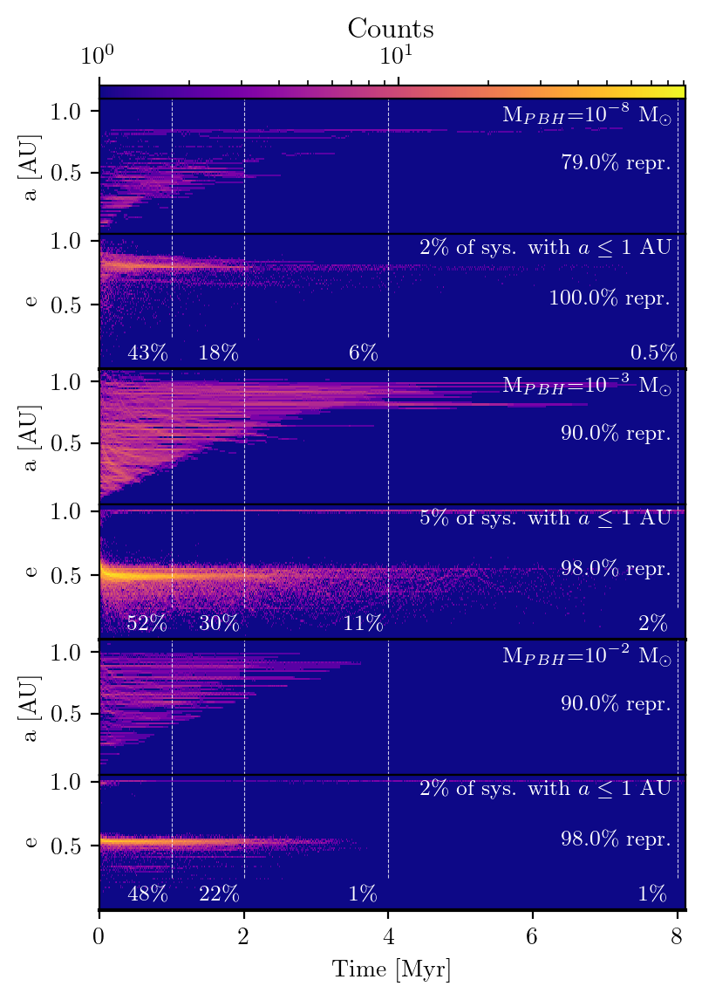

In [ ]:
a_max = 1
plotobj.multiple_analysis_time_series_2dhistogram_multipanel_stacked(
    metric_names=['semi_major_axes', 'eccentricities'],
    metric_ylabels=[r'a [AU]', r'e'],
    time_ylabel=r'Time [Myr]',
    metric_ranges=[(0, a_max+0.1*a_max), (0, 1.05)],
    ticks=[None, [a_max/2, a_max], [0.5, 1.0], None],
    scale=['linear', 'linear', 'linear', 'log'],
    survivor_per_at_t = [1e6, 2e6, 4e6, 8e6],
    time_range=(0, 8.1e6),
    analysis_key=[analysis_list[0].name, analysis_list[-2].name, analysis_list[-1].name],
    unit_change=[1e-6, 1, 1],
    dt_fixed=12,
    metric_bins=75,
    mask_labels=[rf'of sys. with $a \leq$ {a_max} AU', fr'of sys. with $a \leq$ {a_max} AU', None],
    metric_masks=[{
        "type": "where",
        "key": "semi_major_axes",  # Time series of semi-major axes
        "predicate": lambda a_arr: np.mean(a_arr) <= a_max # Average a over time
    },
        {
        "type": "where",
        "key": "semi_major_axes",  # Time series of semi-major axes
        "predicate": lambda a_arr: np.mean(a_arr) <= a_max  # Average a over time
    }], # No mask for orbital_periods
    fig_size=(4, 5),  # Tall figure for 5 analyses × 2 metrics
    save_as=f'stacked_timeseries_histograms_bothmasked_{a_max}au_first_last_8myr.png'
)

## Figure 8


Following cell calculates the number density of systems enclosed in r for each system. n_inner and n_outer parameters denote the r sampling density. Higher this number gets, the accuracy of shell integral and the comupational time increases.

80 80 7.92557452157217
80 80 13.586404317350869


/tmp/ipykernel_2436226/2733797114.py:31: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  plt.scatter(mC/const.M_sun.value, integrated_results[res]['N_eq_full_stars_integrated'], label=r"N$_{eq}(f_{\text{total}})$" if res == 0 else None, c=cmap(5), marker='o', edgecolor='black', s=msize*1.2)
/tmp/ipykernel_2436226/2733797114.py:33: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  plt.scatter(mC/const.M_sun.value, integrated_result

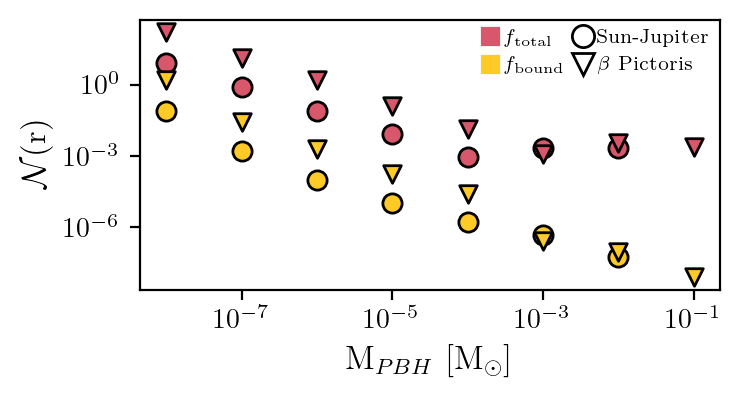

In [ ]:
from matplotlib.lines import Line2D
plt.figure(figsize=(3.5,1.5))
cmap = plt.get_cmap('plasma',10)

n_inner = n_outer = 80
r_edges_inner = np.linspace(0.001, 0.5, n_inner)
r_edges_outer = np.linspace(0.5, 8.0, n_outer)
r_edges = np.unique(np.concatenate([r_edges_inner, r_edges_outer]))

all_results, integrated_results = misc.get_shell_sum_Neq_and_params(
    combined_analysis_list,
    r_edges= r_edges,
    M_star=1.0,
    fraction=0.17,
    save=False,
)
betapic_all_results, betapic_integrated_results = misc.get_shell_sum_Neq_and_params(
    betapic_analysis_list,
    r_edges= r_edges,
    M_star=1.76,
    fraction=0.17,
    save=False,
)

print(n_inner, n_outer, integrated_results[0]["N_eq_full_stars_integrated"])
print(n_inner, n_outer, betapic_integrated_results[1]["N_eq_full_stars_integrated"])

msize = 40
for res in range(len(integrated_results)):
    mC = combined_analysis_list[res].get_system_parameters().get('mC')
    plt.scatter(mC/const.M_sun.value, integrated_results[res]['N_eq_full_stars_integrated'], label=r"N$_{eq}(f_{\text{total}})$" if res == 0 else None, c=cmap(5), marker='o', edgecolor='black', s=msize*1.2)
    # plt.scatter(res, integrated_results[res]['N_eq_full_alike_integrated'], label=f"N_eq full alike", c='green', marker='o', edgecolor='black', s=msize)
    plt.scatter(mC/const.M_sun.value, integrated_results[res]['Neq_pbh_bound_stars_integrated'], label=r"N$_{eq}(f_{\text{bound}})$" if res == 0 else None, c=cmap(8), marker='o', edgecolor='black', s=msize*1.2)
    # plt.scatter(res, integrated_results[res]['Neq_pbh_bound_alike_integrated'], label=f"N_eq pbh bound alike", c='orange', marker='o', edgecolor='black', s=msize)
for res in range(len(betapic_integrated_results)):    
    mC = betapic_analysis_list[res].get_system_parameters().get('mC')
    plt.scatter(mC/const.M_sun.value, betapic_integrated_results[res]['N_eq_full_stars_integrated'],  c=cmap(5), marker='v', edgecolor='black', s=msize)
    plt.scatter(mC/const.M_sun.value, betapic_integrated_results[res]['Neq_pbh_bound_stars_integrated'],  c=cmap(8), marker='v', edgecolor='black', s=msize)

custom_lines = [
    # Color meanings
    Line2D([0], [0], marker='s', color='w', markerfacecolor=cmap(5), markersize=8, markeredgecolor='w', label=r'$f_{\text{total}}$'),
    Line2D([0], [0], marker='s', color='w', markerfacecolor=cmap(8), markersize=8, markeredgecolor='w', label=r'$f_{\text{bound}}$'),
    # Shape meanings
    Line2D([0], [0], marker='o', color='w', markerfacecolor=None, markersize=8, markeredgecolor='black', label='Sun-Jupiter'),
    Line2D([0], [0], marker='v', color='w', markerfacecolor=None, markersize=8, markeredgecolor='black', label=r'$\beta$ Pictoris'),
]
plt.legend(handles=custom_lines, fontsize=7, loc='upper right', frameon=False, ncol=2, handletextpad=0.3, borderaxespad=0.2, borderpad=0.3, handlelength=0.8, columnspacing=0.5)
plt.xlabel(r"M$_{PBH}$ [M$_\odot$]")
plt.ylabel(r"$\mathcal{N}$(r)")
plt.yscale('log')
plt.xscale('log')
plt.subplots_adjust(hspace=0.05, left=0.17, right=0.999, top=0.999, bottom=0.1)
plt.savefig('N_eq_vs_mC.png', dpi=300, bbox_inches='tight')

First dr: 0.0063 kpc, Second dr: 0.0949 kpc
dN/dr first interval: [36.00667685 23.53018666 18.92184667 16.26829433 14.48240509], dN/dr second interval: [3.12604124 2.83780293 2.60124817 2.40090329 2.22711244]
Integrated dN/dr for mC=1.00e-08 Msun: 7.81e+00
First dr: 0.0063 kpc, Second dr: 0.0949 kpc
dN/dr first interval: [3.49299321 2.27946084 1.83233776 1.57509581 1.40204182], dN/dr second interval: [0.30252287 0.27462784 0.25173479 0.2323461  0.21552729]
Integrated dN/dr for mC=1.00e-07 Msun: 7.56e-01
First dr: 0.0063 kpc, Second dr: 0.0949 kpc
dN/dr first interval: [0.36642575 0.23842834 0.19152899 0.16458953 0.14648056], dN/dr second interval: [0.03158763 0.02867488 0.02628444 0.02425994 0.02250379]
Integrated dN/dr for mC=1.00e-06 Msun: 7.89e-02
First dr: 0.0063 kpc, Second dr: 0.0949 kpc
dN/dr first interval: [0.03707993 0.02418163 0.01943582 0.01670631 0.01487035], dN/dr second interval: [0.00320831 0.00291247 0.00266969 0.00246407 0.0022857 ]
Integrated dN/dr for mC=1.00e-05 Ms

/tmp/ipykernel_2436226/3677895021.py:32: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  ax[0].scatter(evenly_sampled_r_array, dndr_by_even_r, c=cmap(j), edgecolor='black', s=30, alpha=1 if i == 6 else 1, zorder=1, transform=shift_transform)
/tmp/ipykernel_2436226/3677895021.py:63: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  ax[1].scatter(evenly_sampled_r_array, dndr_by_even_r, c=cmap(0) if i ==0 else cmap(j), edgecolor='bla

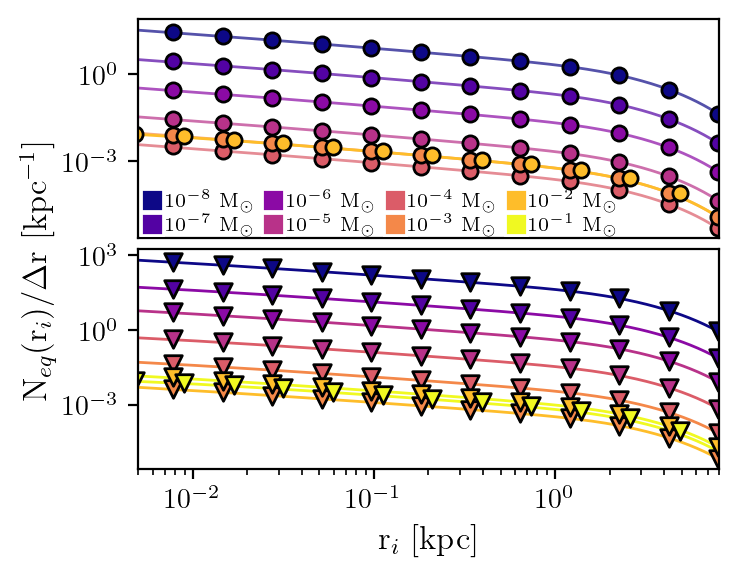

In [ ]:
%matplotlib inline
import src.Utils.plotting_utils as plu
from matplotlib import transforms
linestyles = ['-', '-', '-', '-', '-', '-', '-']
fig, ax = plt.subplots(2, 1, figsize=(3.5, 2.5), sharex=True)
r_array = np.array(list(all_results.keys()))
evenly_sampled_r_array = np.logspace(np.log10(r_array[0]), np.log10(r_array[-1]), len(r_array)//10)
cmap = plt.get_cmap('plasma',8)
k = [0,1, 2, 3, 4, 5, 6]
custom_lines = []

for j, i in enumerate(k):
    mC = combined_analysis_list[i].get_system_parameters().get('mC')/const.M_sun.value
    neq_full_at_r_first = [all_results[r]['N_eq_full_stars'][i] for r in r_array if r <= 0.5]
    neq_full_at_r_second = [all_results[r]['N_eq_full_stars'][i] for r in r_array if r >= 0.5]
    first_dr = r_array[r_array < 0.5][2] - r_array[r_array < 0.5][1]
    second_dr = r_array[r_array >= 0.5][2] - r_array[r_array >= 0.5][1]
    print(f"First dr: {first_dr:.4f} kpc, Second dr: {second_dr:.4f} kpc")
    dndr_first = (neq_full_at_r_first) / first_dr
    dndr_second = (neq_full_at_r_second) / second_dr
    print(f"dN/dr first interval: {dndr_first[:5]}, dN/dr second interval: {dndr_second[:5]}")
    dndr_combined = np.concatenate([dndr_first, dndr_second])
    
    ax[0].plot(r_array, dndr_combined, c=cmap(j), label=fr"{plu.sci_notation_latex(mC)} M$_\odot$", linestyle=linestyles[i % len(linestyles)], linewidth=1, alpha=1 if i == 6 else 0.7, zorder=0)
    # evenly_sampled_r_array = np.logspace(np.log10(r_array[0]) + np.log10((j+1)*0.5), np.log10(r_array[-1] + np.log10((j+1)*0.5)), len(r_array)//12)
    evenly_sampled_r_array = np.logspace(np.log10(r_array[0]), np.log10(r_array[-1]), len(r_array)//12)
    dx = (4)*(1)**j if i == 6 else 0
    dy = 0
    offset = transforms.ScaledTranslation(dx / 72.0, dy / 72.0, fig.dpi_scale_trans)
    shift_transform = ax[0].transData + offset
    dndr_by_even_r = np.interp(evenly_sampled_r_array, r_array, dndr_combined)
    ax[0].scatter(evenly_sampled_r_array, dndr_by_even_r, c=cmap(j), edgecolor='black', s=30, alpha=1 if i == 6 else 1, zorder=1, transform=shift_transform)
    gl_result = calc.integrate_gauss_legendre(r_array, dndr_combined)
    print(f"Integrated dN/dr for mC={mC:.2e} Msun: {gl_result:.2e}")
    custom_lines.append(Line2D([0], [0], marker='s', color='w', markerfacecolor=cmap(j), markersize=8, markeredgecolor='w', label=fr"{plu.sci_notation_latex(mC)} M$_\odot$"))
# turn off the x axis labels for the top plot
ax[0].xaxis.set_visible(False)
# ax[0].set_ylabel(r'N$_{eq}$(r$_i$)/$\Delta$r [kpc$^{-1}$]')
ax[0].set_yscale('log')
ax[0].set_xscale('log')
ax[0].set_xlim(0.005, 8)
r_array = np.array(list(betapic_all_results.keys()))
# linestyles = ['--', '--', '--', '--', '--', '--', '--','--']
k = [0,1, 2, 3, 4, 5, 6, 7]
for j, i in enumerate(k):
    mC = betapic_analysis_list[i].get_system_parameters().get('mC')/const.M_sun.value
    neq_full_at_r_first = [betapic_all_results[r]['N_eq_full_stars'][i] for r in r_array if r <= 0.5]
    neq_full_at_r_second = [betapic_all_results[r]['N_eq_full_stars'][i] for r in r_array if r >= 0.5]
    first_dr = r_array[r_array < 0.5][2] - r_array[r_array < 0.5][1]
    second_dr = r_array[r_array >= 0.5][2] - r_array[r_array >= 0.5][1]
    print(f"First dr: {first_dr:.4f} kpc, Second dr: {second_dr:.4f} kpc")
    dndr_first = (neq_full_at_r_first) / first_dr
    dndr_second = (neq_full_at_r_second) / second_dr
    print(f"dN/dr first interval: {dndr_first[:5]}, dN/dr second interval: {dndr_second[:5]}")
    dndr_combined = np.concatenate([dndr_first, dndr_second])
    evenly_sampled_r_array = np.logspace(np.log10(r_array[0]), np.log10(r_array[-1]), len(r_array)//12)
    dx = (4)*(1)**j if i == 7 else 0
    dy = 0
    offset = transforms.ScaledTranslation(dx / 72.0, dy / 72.0, fig.dpi_scale_trans)
    shift_transform = ax[1].transData + offset
    dndr_by_even_r = np.interp(evenly_sampled_r_array, r_array, dndr_combined)
    ax[1].plot(r_array, dndr_combined, label=fr"{plu.sci_notation_latex(mC)} M$_\odot$" if i == 7 else None, c=cmap(0) if i ==0 else cmap(j+1), linestyle=linestyles[i % len(linestyles)], linewidth=1, zorder=0)
    ax[1].scatter(evenly_sampled_r_array, dndr_by_even_r, c=cmap(0) if i ==0 else cmap(j), edgecolor='black', s=40, marker='v', zorder=1, transform=shift_transform)
    gl_result = calc.integrate_gauss_legendre(r_array, dndr_combined)
    print(f"Integrated dN/dr for mC={mC:.2e} Msun: {gl_result:.2e}")
    if i == 7:
        custom_lines.append(Line2D([0], [0], marker='s', color='w', markerfacecolor=cmap(j), markersize=8, markeredgecolor='w', label=fr"{plu.sci_notation_latex(mC)} M$_\odot$"))

ax[1].set_xlabel(r'r$_i$ [kpc]')
# ax[1].set_ylabel(r'N$_{eq}$(r$_i$)/$\Delta$r [kpc$^{-1}$]')
ax[1].set_yscale('log')
ax[1].set_xscale('log')
ax[1].set_xlim(0.005, 8)
plt.legend(handles=custom_lines, fontsize=7, loc='upper left', frameon=False, ncol=4, columnspacing=0.5, handletextpad=0.3, bbox_to_anchor=(0, 1.3), borderaxespad=0.0, borderpad=0.3, handlelength=0.8, labelspacing=0.05)
fig.text(0.001, 0.5, r'N$_{eq}$(r$_i$)/$\Delta$r [kpc$^{-1}$]', va='center', rotation='vertical')
plt.subplots_adjust(hspace=0.05, left=0.17, right=0.999, top=0.999, bottom=0.1)
plt.savefig('dN_dr_vs_r.png', dpi=300, bbox_inches='tight')

## Figure 10 

This figure requires time averaged values of orital parameters. Creating these arrays takes about 100 minutes.

In [62]:
analyses_with_time_averages = []

for a in analysis_list_a:
    ave_dict = a.get_combined_dictionary(time_averages=True)
    analyses_with_time_averages.append(ave_dict)

Computing time-averaged parameters for cached data. This may take some time...


/grad/a.saricaoglu/.conda/envs/captus/lib/python3.12/site-packages/numpy/_core/fromnumeric.py:3824: RuntimeWarning: Mean of empty slice
  return _methods._mean(a, axis=axis, dtype=dtype,


Computing time-averaged parameters for cached data. This may take some time...
Computing time-averaged parameters for cached data. This may take some time...
Computing time-averaged parameters for cached data. This may take some time...
Computing time-averaged parameters for cached data. This may take some time...
Computing time-averaged parameters for cached data. This may take some time...
Computing time-averaged parameters for cached data. This may take some time...


In [63]:
betapic_analyses_with_time_averages = []

for a in betapic_analysis_list:
    ave_dict = a.get_combined_dictionary(time_averages=True)
    betapic_analyses_with_time_averages.append(ave_dict)

Computing time-averaged parameters for cached data. This may take some time...
Computing time-averaged parameters for cached data. This may take some time...
Computing time-averaged parameters for cached data. This may take some time...
Computing time-averaged parameters for cached data. This may take some time...
Computing time-averaged parameters for cached data. This may take some time...
Computing time-averaged parameters for cached data. This may take some time...
Computing time-averaged parameters for cached data. This may take some time...
Computing time-averaged parameters for cached data. This may take some time...


Note that once the combined dictionary run with time_averages=True, it modifies each analysis object initially given to plotobj class therefore we don't need to recreate plotobj below.

✓ Found in analysis_dict
✓ Found in an_entry
✓ Found in rebound: 1000 entries
1 mask found, combined mask sum: 647
✓ Found in an_entry
2 mask found, combined mask sum: 585
applying mask(s) for analysis Sun_Jupiter_s6_Mpbh1e-02_M4R4C3, v_key V1, metric semi_major_axis_time_avg sum: 585
Applied mask, 585 values after masking
✓ Found in an_entry
✓ Found in rebound: 1000 entries
1 mask found, combined mask sum: 647
✓ Found in an_entry
2 mask found, combined mask sum: 585
applying mask(s) for analysis Sun_Jupiter_s6_Mpbh1e-02_M4R4C3, v_key V1, metric orbital_period_time_avg sum: 585
Applied mask, 585 values after masking
✓ Found in an_entry
✓ Found in rebound: 1000 entries
1 mask found, combined mask sum: 620
✓ Found in an_entry
2 mask found, combined mask sum: 569
applying mask(s) for analysis Sun_Jupiter_s6_Mpbh1e-02_M4R4C3, v_key V4, metric semi_major_axis_time_avg sum: 569
Applied mask, 569 values after masking
✓ Found in an_entry
✓ Found in rebound: 1000 entries
1 mask found, combined 

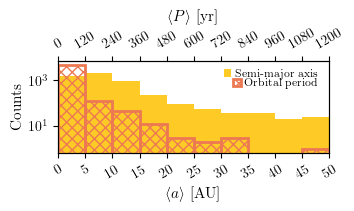

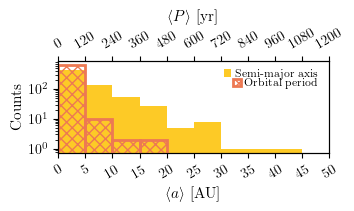

In [17]:
# metric_masks = [[{
#         "type": "where",
#         "key": "semi_major_axis_time_avg",  # Time series of semi-major axes
#         "entry_type": "CatalogEntry",
#         "predicate": lambda a_arr: [a for a in a_arr if a < 55]   # Average a over time
#     }],        ['Same']]
a_lim = 50
P_lim = 'none'
# metric_masks = [[{
#         "key": "semi_major_axis_time_avg",  # Time series of semi-major axes
#         "predicate": lambda a: a < 50  # Average a over time
#     }],        ['Same']]
metric_masks = [[{
        "key": "termination_flag",
        "predicate": lambda a: "escape_B"  in a
    },{
        "key": "semi_major_axis_time_avg",
        "predicate": lambda a: a > 0 and a < a_lim  # Add a > 0
    },
    # {
    #     "key": "orbital_period_time_avg",
    #     "predicate": lambda a: a > 0 and a < P_lim  # Add a > 0
    # } 
    ], [{
        "key": "termination_flag",
        "predicate": lambda a: "escape_B"  in a
    },{
        "key": "semi_major_axis_time_avg",
        "predicate": lambda a: a > 0 and a < a_lim  # Add a > 0
    },
    # {
    #     "key": "orbital_period_time_avg",
    #     "predicate": lambda a: a > 0 and a < P_lim  # Add a > 0
    # } 
    ]]
k = 6
plotobj.multiple_analysis_metric_array_wrt_twinxaxis_stephist(
    metric_lists=[['semi_major_axis_time_avg'], ['orbital_period_time_avg']],
    metric_xlabels=[r'$\langle a \rangle$ [AU]', r'$\langle P \rangle$ [yr]'],
    metric_range=[(None, 50), (None, 1200)],
    bins=[11, 11],
    metric_masks=metric_masks,
    normalization = 2000,
    bin_scale=['log', 'log'],
    unit_change=[1,1, 1],
    metric_scale=['linear', 'linear'],
    labels=[['Semi-major axis'], ['Orbital period']],
    analysis_key=[analysis_list_a[k].name],
    fig_size=(3.5, 1.2), save_as=f'semi_major_axis_and_period_k{k}_histogram_masked_{a_lim}au_exchangeonly.png'
    )
k = 5
plotobj.multiple_analysis_metric_array_wrt_twinxaxis_stephist(
    metric_lists=[['semi_major_axis_time_avg'], ['orbital_period_time_avg']],
    metric_xlabels=[r'$\langle a \rangle$ [AU]', r'$\langle P \rangle$ [yr]'],
    metric_range=[(None, 50), (None, 1200)],
    bins=[11, 11],
    metric_masks=metric_masks,
    normalization = 2000,
    bin_scale=['log', 'log'],
    unit_change=[1,1, 1],
    metric_scale=['linear', 'linear'],
    labels=[['Semi-major axis'], ['Orbital period']],
    analysis_key=[analysis_list_a[k].name],
    fig_size=(3.5, 1.2), save_as=f'semi_major_axis_and_period_k{k}_histogram_masked_{a_lim}au_exchangeonly.png'
    )


✓ Found in analysis_dict
✓ Found in an_entry
✓ Found in rebound: 200 entries
1 mask found, combined mask sum: 135
✓ Found in an_entry
2 mask found, combined mask sum: 119
applying mask(s) for analysis BetaPictoris_s7_Mpbh1e-01_M4R4C3, v_key V1, metric semi_major_axis_time_avg sum: 119
Applied mask, 119 values after masking
✓ Found in an_entry
✓ Found in rebound: 200 entries
1 mask found, combined mask sum: 135
✓ Found in an_entry
2 mask found, combined mask sum: 119
applying mask(s) for analysis BetaPictoris_s7_Mpbh1e-01_M4R4C3, v_key V1, metric orbital_period_time_avg sum: 119
Applied mask, 119 values after masking
✓ Found in an_entry
✓ Found in rebound: 200 entries
1 mask found, combined mask sum: 147
✓ Found in an_entry
2 mask found, combined mask sum: 121
applying mask(s) for analysis BetaPictoris_s7_Mpbh1e-01_M4R4C3, v_key V4, metric semi_major_axis_time_avg sum: 121
Applied mask, 121 values after masking
✓ Found in an_entry
✓ Found in rebound: 200 entries
1 mask found, combined m

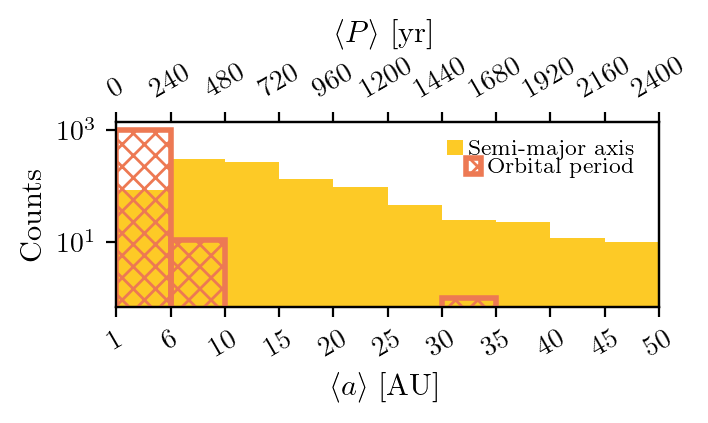

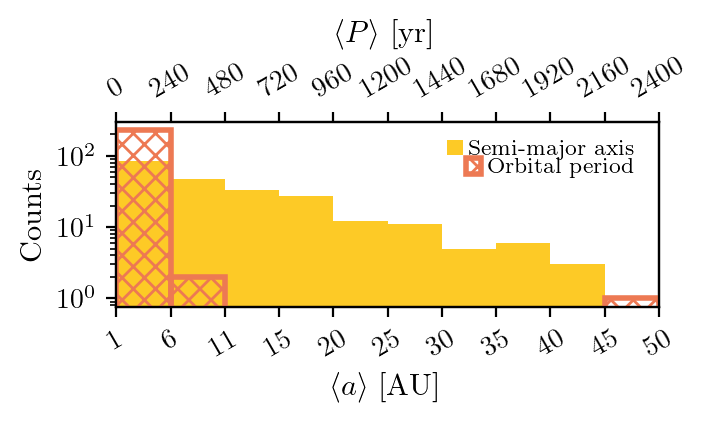

In [52]:
# metric_masks = [[{
#         "type": "where",
#         "key": "semi_major_axis_time_avg",  # Time series of semi-major axes
#         "entry_type": "CatalogEntry",
#         "predicate": lambda a_arr: [a for a in a_arr if a < 55]   # Average a over time
#     }],        ['Same']]
a_lim = 50
P_lim = None
# metric_masks = [[{
#         "key": "semi_major_axis_time_avg",  # Time series of semi-major axes
#         "predicate": lambda a: a < 50  # Average a over time
#     }],        ['Same']]
metric_masks = [[{
        "key": "termination_flag",
        "predicate": lambda a: "escape_B" in a
    },{
        "key": "semi_major_axis_time_avg",
        "predicate": lambda a: a > 0.3 and a < a_lim  # Add a > 0
    },
    # {
    #     "key": "orbital_period_time_avg",
    #     "predicate": lambda a: a > 0 and a < P_lim  # Add a > 0
    # } 
    ], [{
        "key": "termination_flag",
        "predicate": lambda a: "escape_B"  in a
    },{
        "key": "semi_major_axis_time_avg",
        "predicate": lambda a: a > 0.3 and a < a_lim  # Add a > 0
    },
    # {
    #     "key": "orbital_period_time_avg",
    #     "predicate": lambda a: a > 0 and a < P_lim  # Add a > 0
    # } 
    ]]
k = 7
plotobj_bp.multiple_analysis_metric_array_wrt_twinxaxis_stephist(
    metric_lists=[['semi_major_axis_time_avg'], ['orbital_period_time_avg']],
    metric_xlabels=[r'$\langle a \rangle$ [AU]', r'$\langle P \rangle$ [yr]'],
    metric_range=[(None, 50), (None, 2400)],
    bins=[11, 11],
    metric_masks=metric_masks,
    normalization = 2000,
    bin_scale=['log', 'log'],
    unit_change=[1,1,1],
    metric_scale=['linear', 'linear'],
    labels=[['Semi-major axis'], ['Orbital period']],
    analysis_key=[betapic_analysis_list[k].name],
    fig_size=(3.5, 1.2), save_as=f'betapic_semi_major_axis_and_period_k{k}_histogram_masked_{a_lim}au_exchangeonly.png'
    )
k = 6
plotobj_bp.multiple_analysis_metric_array_wrt_twinxaxis_stephist(
    metric_lists=[['semi_major_axis_time_avg'], ['orbital_period_time_avg']],
    metric_xlabels=[r'$\langle a \rangle$ [AU]', r'$\langle P \rangle$ [yr]'],
    metric_range=[(None, 50), (None,2400)],
    bins=[11, 11],
    metric_masks=metric_masks,
    normalization = 2000,
    bin_scale=['log', 'log'],
    unit_change=[1,1,1],
    metric_scale=['linear', 'linear'],
    labels=[['Semi-major axis'], ['Orbital period']],
    analysis_key=[betapic_analysis_list[k].name],
    fig_size=(3.5, 1.2), save_as=f'betapic_semi_major_axis_and_period_k{k}_histogram_masked_{a_lim}au_exchangeonly.png'
)

## Figure 12

✓ Found in analysis_dict
✓ Found in an_entry
✓ Found in rebound: 1000 entries
1 mask found, combined mask sum: 353
✓ Found in an_entry
2 mask found, combined mask sum: 206
applying mask(s) for analysis Sun_Jupiter_s6_Mpbh1e-02_M4R4C3, v_key V1, metric semi_major_axis_time_avg sum: 206
Applied mask, 206 values after masking
✓ Found in an_entry
✓ Found in rebound: 1000 entries
1 mask found, combined mask sum: 353
✓ Found in an_entry
2 mask found, combined mask sum: 206
applying mask(s) for analysis Sun_Jupiter_s6_Mpbh1e-02_M4R4C3, v_key V1, metric orbital_period_time_avg sum: 206
Applied mask, 206 values after masking
✓ Found in an_entry
✓ Found in rebound: 1000 entries
1 mask found, combined mask sum: 380
✓ Found in an_entry
2 mask found, combined mask sum: 243
applying mask(s) for analysis Sun_Jupiter_s6_Mpbh1e-02_M4R4C3, v_key V4, metric semi_major_axis_time_avg sum: 243
Applied mask, 243 values after masking
✓ Found in an_entry
✓ Found in rebound: 1000 entries
1 mask found, combined 

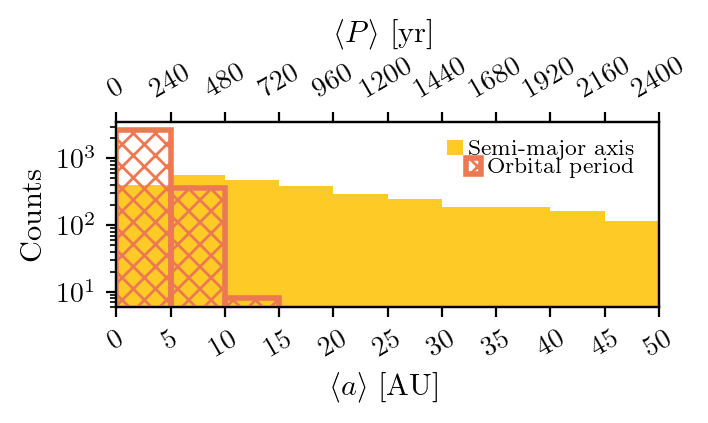

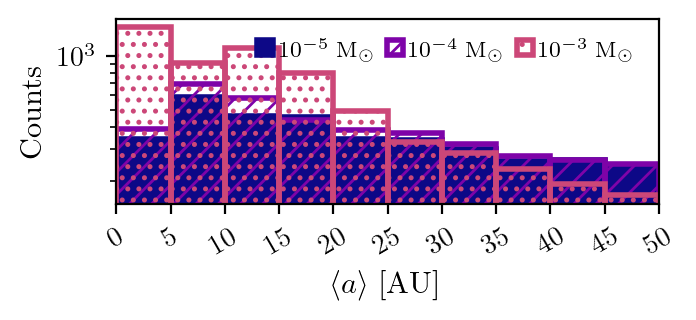

In [60]:
# metric_masks = [[{
#         "type": "where",
#         "key": "semi_major_axis_time_avg",  # Time series of semi-major axes
#         "entry_type": "CatalogEntry",
#         "predicate": lambda a_arr: [a for a in a_arr if a < 55]   # Average a over time
#     }],        ['Same']]
a_lim = 50
P_lim = 'none'
# metric_masks = [[{
#         "key": "semi_major_axis_time_avg",  # Time series of semi-major axes
#         "predicate": lambda a: a < 50  # Average a over time
#     }],        ['Same']]
metric_masks = [[{
        "key": "termination_flag",
        "predicate": lambda a: "escape_B" not in a
    },{
        "key": "semi_major_axis_time_avg",
        "predicate": lambda a: a > 0.3 and a < a_lim  # Add a > 0
    },
    # {
    #     "key": "orbital_period_time_avg",
    #     "predicate": lambda a: a > 0 and a < P_lim  # Add a > 0
    # } 
    ], [{
        "key": "termination_flag",
        "predicate": lambda a: "escape_B" not in a
    },{
        "key": "semi_major_axis_time_avg",
        "predicate": lambda a: a > 0.3 and a < a_lim  # Add a > 0
    },
    # {
    #     "key": "orbital_period_time_avg",
    #     "predicate": lambda a: a > 0 and a < P_lim  # Add a > 0
    # } 
    ]]
k = 6
plotobj.multiple_analysis_metric_array_wrt_twinxaxis_stephist(
    metric_lists=[['semi_major_axis_time_avg'], ['orbital_period_time_avg']],
    metric_xlabels=[r'$\langle a \rangle$ [AU]', r'$\langle P \rangle$ [yr]'],
    metric_range=[(None, 50), (None, 2400)],
    bins=[11, 11],
    metric_masks=metric_masks,
    normalization = 2000,
    bin_scale=['log', 'log'],
    unit_change=[1,1, 1],
    metric_scale=['linear', 'linear'],
    labels=[['Semi-major axis'], ['Orbital period']],
    analysis_key=[analysis_list_a[k].name],
    fig_size=(3.5, 1.2), save_as=f'semi_major_axis_and_period_k{k}_histogram_masked_{a_lim}au_noexchange.png'
    )
k = 5
plotobj.multiple_analysis_metric_array_wrt_twinxaxis_stephist(
    metric_lists=[['semi_major_axis_time_avg'], None],
    metric_xlabels=[r'$\langle a \rangle$ [AU]', None],
    metric_range=[None, None],
    bins=[11],
    metric_masks=metric_masks,
    normalization = 2000,
    bin_scale=['log', None],
    metric_scale=['linear', None],
    ticks=[None, None],
    # labels=[['Semi-major Axes'], None],
    analysis_key=[analysis_list_a[-2].name, analysis_list_a[-3].name, analysis_list_a[-4].name],
    fig_size=(3.5, 1.2), save_as=f'semi_major_axis_histogram_masked_{a_lim}au_noexchange.png'
    )

✓ Found in analysis_dict
✓ Found in an_entry
✓ Found in rebound: 200 entries
1 mask found, combined mask sum: 65
✓ Found in an_entry
2 mask found, combined mask sum: 27
applying mask(s) for analysis BetaPictoris_s7_Mpbh1e-01_M4R4C3, v_key V1, metric semi_major_axis_time_avg sum: 27
Applied mask, 27 values after masking
✓ Found in an_entry
✓ Found in rebound: 200 entries
1 mask found, combined mask sum: 65
✓ Found in an_entry
2 mask found, combined mask sum: 27
applying mask(s) for analysis BetaPictoris_s7_Mpbh1e-01_M4R4C3, v_key V1, metric orbital_period_time_avg sum: 27
Applied mask, 27 values after masking
✓ Found in an_entry
✓ Found in rebound: 200 entries
1 mask found, combined mask sum: 53
✓ Found in an_entry
2 mask found, combined mask sum: 25
applying mask(s) for analysis BetaPictoris_s7_Mpbh1e-01_M4R4C3, v_key V4, metric semi_major_axis_time_avg sum: 25
Applied mask, 25 values after masking
✓ Found in an_entry
✓ Found in rebound: 200 entries
1 mask found, combined mask sum: 53


/data/a.saricaoglu/repo/captus/src/ThreeBodyCapture/Plotting/plotting.py:5950: UserWarning: Attempt to set non-positive ylim on a log-scaled axis will be ignored.
  ax_bottom.set_ylim(0, ax_bottom.get_ylim()[1]*1.2)


✓ Saved: betapic_semi_major_axis_histogram_masked_50au_noexchange.png


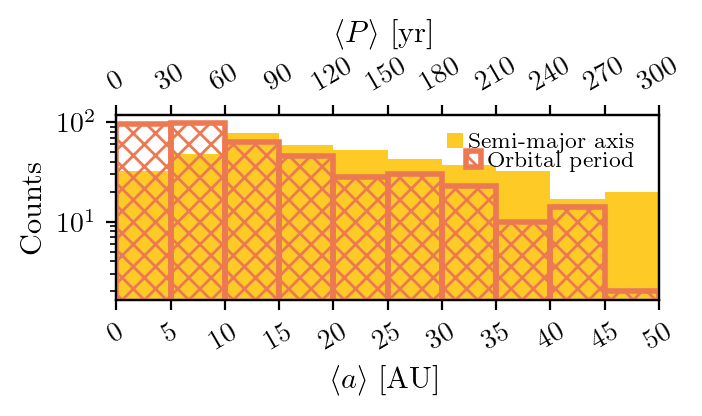

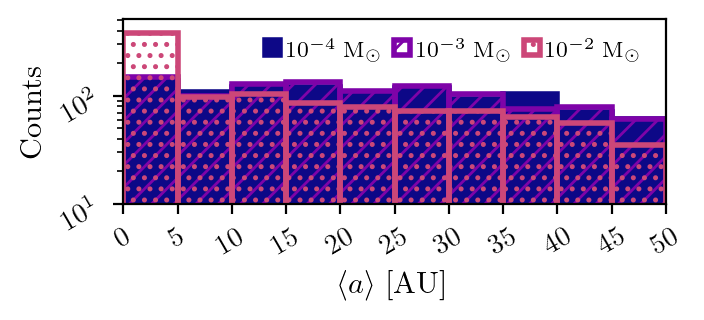

In [10]:
# metric_masks = [[{
#         "type": "where",
#         "key": "semi_major_axis_time_avg",  # Time series of semi-major axes
#         "entry_type": "CatalogEntry",
#         "predicate": lambda a_arr: [a for a in a_arr if a < 55]   # Average a over time
#     }],        ['Same']]
a_lim = 50
P_lim = None
# metric_masks = [[{
#         "key": "semi_major_axis_time_avg",  # Time series of semi-major axes
#         "predicate": lambda a: a < 50  # Average a over time
#     }],        ['Same']]
metric_masks = [[{
        "key": "termination_flag",
        "predicate": lambda a: "escape_B" not in a
    },{
        "key": "semi_major_axis_time_avg",
        "predicate": lambda a: a > 0 and a < a_lim  # Add a > 0
    },
    # {
    #     "key": "orbital_period_time_avg",
    #     "predicate": lambda a: a > 0 and a < P_lim  # Add a > 0
    # } 
    ], [{
        "key": "termination_flag",
        "predicate": lambda a: "escape_B" not in a
    },{
        "key": "semi_major_axis_time_avg",
        "predicate": lambda a: a > 0 and a < a_lim  # Add a > 0
    },
    # {
    #     "key": "orbital_period_time_avg",
    #     "predicate": lambda a: a > 0 and a < P_lim  # Add a > 0
    # } 
    ]]
k = 7
plotobj_bp.multiple_analysis_metric_array_wrt_twinxaxis_stephist(
    metric_lists=[['semi_major_axis_time_avg'], ['orbital_period_time_avg']],
    metric_xlabels=[r'$\langle a \rangle$ [AU]', r'$\langle P \rangle$ [yr]'],
    metric_range=[(None, 50), (None, 300)],
    bins=[11, 11],
    metric_masks=metric_masks,
    normalization = 2000,
    bin_scale=['log', 'log'],
    unit_change=[1,1,1],
    metric_scale=['linear', 'linear'],
    labels=[['Semi-major axis'], ['Orbital period']],
    analysis_key=[betapic_analysis_list[k].name],
    fig_size=(3.5, 1.2), save_as=f'betapic_semi_major_axis_and_period_k{k}_histogram_masked_{a_lim}au_noexchange.png'
    )
plotobj_bp.multiple_analysis_metric_array_wrt_twinxaxis_stephist(
    metric_lists=[['semi_major_axis_time_avg'], None],
    metric_xlabels=[r'$\langle a \rangle$ [AU]', None],
    metric_range=[None, None],
    bins=[11],
    metric_masks=metric_masks,
    normalization = 2000,
    bin_scale=['log', None],
    metric_scale=['linear', None],
    ticks=[None, [10, 100]],
    # labels=[['Semi-major Axes'], None],
    analysis_key=[betapic_analysis_list[-2].name, betapic_analysis_list[-3].name, betapic_analysis_list[-4].name],
    fig_size=(3.5, 1.2), save_as=f'betapic_semi_major_axis_histogram_masked_{a_lim}au_noexchange.png'
    )

## Figure 11 and 13
For these figures, we need to import the exoplanets data first.

In [67]:
exoplanet_df = pd.read_csv(
    os.path.join(Path.cwd(), "../data", "exoplanets.csv")
)

# Extract high eccentricity planets with no determined radius
print("Total planets in dataset:", len(exoplanet_df))
print(f"keys: {exoplanet_df.keys()}")


Total planets in dataset: 6291
keys: Index(['pl_name', 'hostname', 'default_flag', 'sy_snum', 'sy_pnum',
       'discoverymethod', 'disc_year', 'disc_facility', 'soltype',
       'pl_controv_flag', 'pl_refname', 'pl_orbper', 'pl_orbpererr1',
       'pl_orbpererr2', 'pl_orbperlim', 'pl_orbsmax', 'pl_orbsmaxerr1',
       'pl_orbsmaxerr2', 'pl_orbsmaxlim', 'pl_rade', 'pl_radeerr1',
       'pl_radeerr2', 'pl_radelim', 'pl_radj', 'pl_radjerr1', 'pl_radjerr2',
       'pl_radjlim', 'pl_bmasse', 'pl_bmasseerr1', 'pl_bmasseerr2',
       'pl_bmasselim', 'pl_bmassj', 'pl_bmassjerr1', 'pl_bmassjerr2',
       'pl_bmassjlim', 'pl_bmassprov', 'pl_orbeccen', 'pl_orbeccenerr1',
       'pl_orbeccenerr2', 'pl_orbeccenlim', 'pl_insol', 'pl_insolerr1',
       'pl_insolerr2', 'pl_insollim', 'pl_eqt', 'pl_eqterr1', 'pl_eqterr2',
       'pl_eqtlim', 'ttv_flag', 'st_refname', 'st_spectype', 'st_teff',
       'st_tefferr1', 'st_tefferr2', 'st_tefflim', 'st_rad', 'st_raderr1',
       'st_raderr2', 'st_radlim', '

In [68]:
# Systems with stellar masses aroun 1.75 solar masses with planet masses around 1-100 jupiter masses seem to be the ones with high eccentricity and no radius measurements. This could be due to observational biases or intrinsic properties of those systems. Further investigation would be needed to understand the underlying reasons for this pattern.
sun_mass_stars = exoplanet_df[exoplanet_df['st_mass'].between(0.5, 8)]
jupiter_mass_planets = exoplanet_df[exoplanet_df['pl_bmassj'].between(0.15, 30)]
sun_mass_stars_with_jupiter_planets = sun_mass_stars[sun_mass_stars['pl_bmassj'].between(0.15, 30)]
sun_mass_stars_with_jupiter_planets_single_planet_star = sun_mass_stars_with_jupiter_planets[(sun_mass_stars_with_jupiter_planets['sy_pnum'] == 1) & (sun_mass_stars_with_jupiter_planets['sy_snum'] == 1)]
sms_w_jmp_sps_microlensing = sun_mass_stars_with_jupiter_planets_single_planet_star[sun_mass_stars_with_jupiter_planets_single_planet_star['discoverymethod'] == 'Microlensing']
print(len(sun_mass_stars_with_jupiter_planets))
print(len(sun_mass_stars_with_jupiter_planets_single_planet_star))
print(len(sms_w_jmp_sps_microlensing))

sun_mass_stars_with_double_planets = sun_mass_stars[(sun_mass_stars['sy_pnum'] == 2) & (sun_mass_stars['sy_snum'] == 1)]
sms_w_jmp_dps_microlensing = sun_mass_stars_with_double_planets[sun_mass_stars_with_double_planets['discoverymethod'] == 'Microlensing']
print(len(sun_mass_stars_with_double_planets))
print(len(sms_w_jmp_dps_microlensing))



1706
1021
68
875
8


In [145]:
# add solar system planets to the plot
nan_ecc_mask = np.isnan(sms_w_jmp_sps_microlensing['pl_orbeccen'].values)
# now reverse the mask to get only valid eccentricities
valid_ecc_mask = ~nan_ecc_mask
print(f"Valid eccentricity mask: {valid_ecc_mask}")

# find min and max of pl_orbsmax in sms_w_jmp_sps_microlensing without NaN values
nan_semax_mask = np.isnan(sms_w_jmp_sps_microlensing['pl_orbsmax'].values)
valid_orbsmax = (sms_w_jmp_sps_microlensing['pl_orbsmax'].values)[~nan_semax_mask]
valid_orbsmax_err = (-sms_w_jmp_sps_microlensing['pl_orbsmaxerr2'].values)[valid_ecc_mask], (sms_w_jmp_sps_microlensing['pl_orbsmaxerr1'].values)[valid_ecc_mask]
valid_orbeccen_err = (-sms_w_jmp_sps_microlensing['pl_orbeccenerr2'].values)[valid_ecc_mask], (sms_w_jmp_sps_microlensing['pl_orbeccenerr1'].values)[valid_ecc_mask]
min_orbsmax = np.min(valid_orbsmax)
max_orbsmax = np.max(valid_orbsmax)
print(f"Microlensing pl_orbsmax range: {min_orbsmax:.2f} AU to {max_orbsmax:.2f} AU")

solar_system_planets = {
    'Mercury': {'a': 0.39, 'e': 0.205, 'a_error': (0.0015*u.m).to(u.au).value, 'e_error': 4.24e-12},
    'Venus': {'a': 0.72, 'e': 0.007, 'a_error': (0.0065*u.m).to(u.au).value, 'e_error': 1.03e-12},
    'Earth': {'a': 1.00, 'e': 0.017, 'a_error': (0.013*u.m).to(u.au).value, 'e_error': 2.93e-12},
    'Mars': {'a': 1.52, 'e': 0.093, 'a_error': (0.0487*u.m).to(u.au).value, 'e_error': 9.55e-13},
    'Jupiter': {'a': 5.20, 'e': 0.048, 'a_error': (372*u.m).to(u.au).value, 'e_error': 1.02e-9},
    'Saturn': {'a': 9.58, 'e': 0.056, 'a_error': (16.936*u.m).to(u.au).value, 'e_error': 2.12e-11},
    'Uranus': {'a': 19.20, 'e': 0.046, 'a_error': (31314*u.m).to(u.au).value, 'e_error': 1.71e-8},
    'Neptune': {'a': 30.05, 'e': 0.010, 'a_error': (288035*u.m).to(u.au).value, 'e_error': 7.52e-8},
}
# create a merged x array with sms_w_jmp_sps_microlensing and solar system planets
merged_x = np.concatenate([(sms_w_jmp_sps_microlensing['pl_orbsmax'].values)[~nan_ecc_mask], [p['a'] for p in solar_system_planets.values()]])
merged_y = np.concatenate([(sms_w_jmp_sps_microlensing['pl_orbeccen'].values)[~nan_ecc_mask], [p['e'] for p in solar_system_planets.values()]])
merged_x_err = (np.concatenate([valid_orbsmax_err[0], [p['a_error'] for p in solar_system_planets.values()]]) , np.concatenate([valid_orbsmax_err[1], [p['a_error'] for p in solar_system_planets.values()]]))
merged_y_err = (np.concatenate([valid_orbeccen_err[0], [p['e_error'] for p in solar_system_planets.values()]]) , np.concatenate([valid_orbeccen_err[1], [p['e_error'] for p in solar_system_planets.values()]]))


Valid eccentricity mask: [False False False False False False False False False False False False
 False False False False False False False False False False False False
 False False False False False False False False False False False False
 False False False False False False False False False False False False
 False False False  True False False False False False False  True False
 False False False False False False False False]
Microlensing pl_orbsmax range: 1.10 AU to 8.30 AU


✓ Found in analysis_dict
✓ Found in analysis_dict

Processing analysis Sun_Jupiter_s5_Mpbh1e-03_M4R4C3 with zkey 1.000e-03 M$_{\odot}$
✓ Found in an_entry
✓ Found in rebound: 1000 entries
1 mask found, combined mask sum: 69
✓ Found in an_entry
2 mask found, combined mask sum: 69
Applied mask, 69 values after masking
✓ Found in an_entry
✓ Found in rebound: 1000 entries
1 mask found, combined mask sum: 69
✓ Found in an_entry
2 mask found, combined mask sum: 69
Applied mask, 69 values after masking
✓ Found in an_entry
✓ Found in rebound: 1000 entries
1 mask found, combined mask sum: 54
✓ Found in an_entry
2 mask found, combined mask sum: 54
Applied mask, 54 values after masking
✓ Found in an_entry
✓ Found in rebound: 1000 entries
1 mask found, combined mask sum: 54
✓ Found in an_entry
2 mask found, combined mask sum: 54
Applied mask, 54 values after masking
✓ Found in an_entry
✓ Found in rebound: 1000 entries
1 mask found, combined mask sum: 51
✓ Found in an_entry
2 mask found, combined m

/grad/a.saricaoglu/.conda/envs/captus/lib/python3.12/site-packages/seaborn/distributions.py:1176: UserWarning: linewidths is ignored by contourf
  cset = contour_func(


  0 outliers detected
Average x value: 8.23, Average y value: 0.52
✓ Found in analysis_dict
✓ Found in analysis_dict

Processing analysis BetaPictoris_s6_Mpbh1e-02_M4R4C3 with zkey 1.000e-02 M$_{\odot}$
✓ Found in an_entry
✓ Found in rebound: 200 entries
1 mask found, combined mask sum: 24
✓ Found in an_entry
2 mask found, combined mask sum: 22
Applied mask, 22 values after masking
✓ Found in an_entry
✓ Found in rebound: 200 entries
1 mask found, combined mask sum: 24
✓ Found in an_entry
2 mask found, combined mask sum: 22
Applied mask, 22 values after masking
✓ Found in an_entry
✓ Found in rebound: 200 entries
1 mask found, combined mask sum: 21
✓ Found in an_entry
2 mask found, combined mask sum: 21
Applied mask, 21 values after masking
✓ Found in an_entry
✓ Found in rebound: 200 entries
1 mask found, combined mask sum: 21
✓ Found in an_entry
2 mask found, combined mask sum: 21
Applied mask, 21 values after masking
✓ Found in an_entry
✓ Found in rebound: 200 entries
1 mask found, com

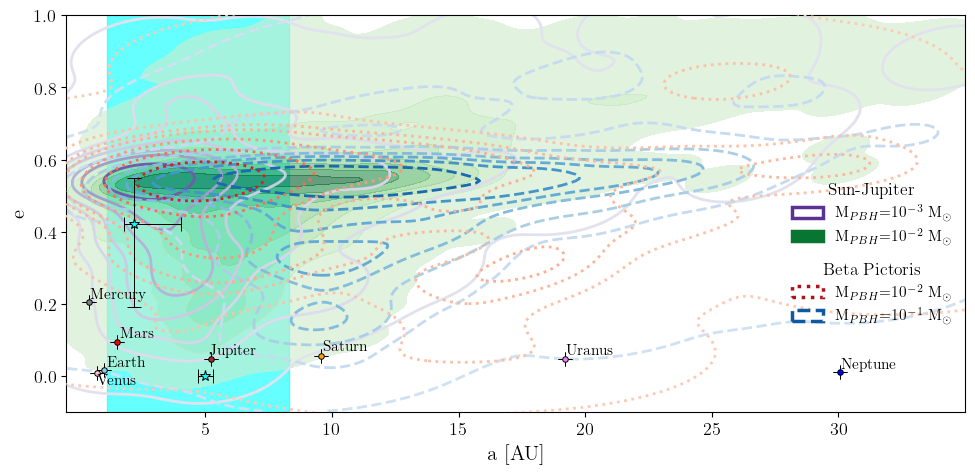

In [ ]:
# Create a single figure with one axis
fig, ax = plt.subplots(figsize=(10, 5))
# Set font size for all text in the figure
plt.rcParams.update({'font.size': 20})
a_lim = 50
metric_masks = [[{
        "key": "termination_flag",
        "predicate": lambda a: "escape_B"  in a
    },{
        "key": "semi_major_axis_time_avg",
        "predicate": lambda a: a > 0 and a < a_lim  # Add a > 0
    },

    ], [{
        "key": "termination_flag",
        "predicate": lambda a: "escape_B"  in a
    },{
        "key": "semi_major_axis_time_avg",
        "predicate": lambda a: a > 0 and a < a_lim  # Add a > 0
    },

    ]]
plotobj.plot_kde(
         metric_lists=[['semi_major_axis_time_avg', 'eccentricity_time_avg']],      
         metric_labels=[r'a [AU]', r'e'],
         scale=('linear', 'linear', 'linear'),
         ranges=[(-0.5, 35), (-0.1, 1)],
         cmaps = ['Purples','Greens',],
         bw_adjust=0.7,
         thresh=0.001,
         levels=8,
         alpha=[1.0, 0.6, 1],
         fill=[False,  True, False],
         metric_masks=metric_masks,
         analysis_key=[analysis_list_a[-1].name, analysis_list_a[-2].name],
         zorder=[2, 1, 1],
         linestyle=['-', '-', '-'],
         linewidth=[2.0, 0.0, 1.0],
         fig_size= (3.5, 3.5),
         ticks=[(5, 10, 15, 20, 25, 30), (0, 0.2, 0.4, 0.6, 0.8, 1)],
         fontsize=15,
         ax =ax,
         legend_title='Sun-Jupiter',
         legend_position=(1.0, 0.5),
         save=False,
         save_as='sj_planets_a_e_kde_50au.png')

a_lim = 50
metric_masks = [[{
        "key": "termination_flag",
        "predicate": lambda a: "escape_B"  in a
    },{
        "key": "semi_major_axis_time_avg",
        "predicate": lambda a: a > 0 and a < a_lim  # Add a > 0
    },

    ], [{
        "key": "termination_flag",
        "predicate": lambda a: "escape_B"  in a
    },{
        "key": "semi_major_axis_time_avg",
        "predicate": lambda a: a > 0 and a < a_lim  # Add a > 0
    },

    ]]
plotobj_bp.plot_kde(
         metric_lists=[['semi_major_axis_time_avg', 'eccentricity_time_avg']],      
         metric_labels=[r'a [AU]', r'e'],
         scale=('linear', 'linear', 'linear'),
         ranges=[(-0.5, 35), (-0.1, 1)],
         cmaps = ['Reds','Blues'],
         bw_adjust=0.7,
         thresh=0.0001,
         levels=8,
         alpha=[1, 1, 1],
         fill=[False,  False, False],
         metric_masks=metric_masks,
         analysis_key=[betapic_analysis_list[-1].name, betapic_analysis_list[-2].name],
         zorder=[3, 2, 1],
         linestyle=[':', '--', '-'],
         linewidth=[2, 2, 1],
         fig_size= (3.5, 3.5),
         ticks=[(5, 10, 15, 20, 25, 30), (0, 0.2, 0.4, 0.6, 0.8, 1)],
         ax =ax,
         fontsize=15,
         legend_title="Beta Pictoris",
         legend_position=(1.0, 0.3),
         extra_scatters=[
            {
                "x": merged_x,
                "y": merged_y,
                "x_err": merged_x_err,
                "y_err": merged_y_err,
                "marker": ['*']*len((sms_w_jmp_sps_microlensing['pl_orbsmax'].values)[~nan_ecc_mask]) + ['o']*len(solar_system_planets),
                "mfc": ['cyan']*len((sms_w_jmp_sps_microlensing['pl_orbsmax'].values)[~nan_ecc_mask]) + ['gray', 'pink', 'skyblue', 'red', 'brown', 'orange', 'violet', 'blue'],
                "edgecolors": 'black',
                "s": [8]*len((sms_w_jmp_sps_microlensing['pl_orbsmax'].values)[~nan_ecc_mask]) + [4]*len(solar_system_planets),
                # "mew": 0.1,
                "label": "Sun-like Stars with Jovian Planets",
                "text" : [None, None, 'Mercury', 'Venus', 'Earth', 'Mars', 'Jupiter', 'Saturn', 'Uranus', 'Neptune'],  # Add symbols for solar system planets),
                "text_color": 'black',  # ← Custom text color
                "linewidths": 0.7,
                "capsize": 5,
                "fontsize": 11,
                "xytext": [(1,1), (2,1),(1, 1), (0,-10), (2,0), (2,1), (-1,1), (1,1), (1,1), (1,1)],  # Offset for text labels
            }
                ],

         extra_fills=[
        # For first dataset: shade uncertainty region
        
            {
                "x": np.array([min_orbsmax, max_orbsmax]),
                "color": "cyan",
                "alpha": 0.6,
                "label": "Microlensing Detection Range",
                "zorder": 0
            }
        ],
         save=True,
         save_as='combined_kde_exchange.png')


In [148]:
# add solar system planets to the plot

print(sms_w_jmp_dps_microlensing['pl_orbeccen'].values)
nan_ecc_mask = np.isnan(sms_w_jmp_dps_microlensing['pl_orbeccen'].values)
# now reverse the mask to get only valid eccentricities
valid_ecc_mask = ~nan_ecc_mask
print(f"Valid eccentricity mask: {valid_ecc_mask}")

# find min and max of pl_orbsmax in sms_w_jmp_dps_microlensing without NaN values
nan_semax_mask = np.isnan(sms_w_jmp_dps_microlensing['pl_orbsmax'].values)
valid_orbsmax = (sms_w_jmp_dps_microlensing['pl_orbsmax'].values)[~nan_semax_mask]
valid_orbsmax_err = (-sms_w_jmp_dps_microlensing['pl_orbsmaxerr2'].values)[valid_ecc_mask], (sms_w_jmp_dps_microlensing['pl_orbsmaxerr1'].values)[valid_ecc_mask]
valid_orbeccen_err = (-sms_w_jmp_dps_microlensing['pl_orbeccenerr2'].values)[valid_ecc_mask], (sms_w_jmp_dps_microlensing['pl_orbeccenerr1'].values)[valid_ecc_mask]
min_orbsmax = np.min(valid_orbsmax)
max_orbsmax = np.max(valid_orbsmax)
print(f"Microlensing pl_orbsmax range: {min_orbsmax:.2f} AU to {max_orbsmax:.2f} AU")

# create a merged x array with sms_w_jmp_dps_microlensing and solar system planets
merged_x = np.concatenate([(sms_w_jmp_dps_microlensing['pl_orbsmax'].values)[~nan_ecc_mask], [p['a'] for p in solar_system_planets.values()]])
merged_y = np.concatenate([(sms_w_jmp_dps_microlensing['pl_orbeccen'].values)[~nan_ecc_mask], [p['e'] for p in solar_system_planets.values()]])
merged_x_err = (np.concatenate([valid_orbsmax_err[0], [p['a_error'] for p in solar_system_planets.values()]]) , np.concatenate([valid_orbsmax_err[1], [p['a_error'] for p in solar_system_planets.values()]]))
merged_y_err = (np.concatenate([valid_orbeccen_err[0], [p['e_error'] for p in solar_system_planets.values()]]) , np.concatenate([valid_orbeccen_err[1], [p['e_error'] for p in solar_system_planets.values()]]))


[ nan  nan  nan 0.15  nan  nan  nan  nan]
Valid eccentricity mask: [False False False  True False False False False]
Microlensing pl_orbsmax range: 2.30 AU to 12.60 AU


✓ Found in analysis_dict
✓ Found in analysis_dict

Processing analysis Sun_Jupiter_s5_Mpbh1e-03_M4R4C3 with zkey 1.000e-03 M$_{\odot}$
✓ Found in an_entry
✓ Found in rebound: 1000 entries
1 mask found, combined mask sum: 931
✓ Found in an_entry
2 mask found, combined mask sum: 542
Applied mask, 542 values after masking
✓ Found in an_entry
✓ Found in rebound: 1000 entries
1 mask found, combined mask sum: 931
✓ Found in an_entry
2 mask found, combined mask sum: 542
Applied mask, 542 values after masking
✓ Found in an_entry
✓ Found in rebound: 1000 entries
1 mask found, combined mask sum: 946
✓ Found in an_entry
2 mask found, combined mask sum: 547
Applied mask, 547 values after masking
✓ Found in an_entry
✓ Found in rebound: 1000 entries
1 mask found, combined mask sum: 946
✓ Found in an_entry
2 mask found, combined mask sum: 547
Applied mask, 547 values after masking
✓ Found in an_entry
✓ Found in rebound: 1000 entries
1 mask found, combined mask sum: 949
✓ Found in an_entry
2 mask foun

/grad/a.saricaoglu/.conda/envs/captus/lib/python3.12/site-packages/seaborn/distributions.py:1176: UserWarning: linewidths is ignored by contourf
  cset = contour_func(


  0 outliers detected
Average x value: 14.56, Average y value: 0.75
✓ Found in analysis_dict
✓ Found in analysis_dict

Processing analysis BetaPictoris_s6_Mpbh1e-02_M4R4C3 with zkey 1.000e-02 M$_{\odot}$
✓ Found in an_entry
✓ Found in rebound: 200 entries
1 mask found, combined mask sum: 176
✓ Found in an_entry
2 mask found, combined mask sum: 88
Applied mask, 88 values after masking
✓ Found in an_entry
✓ Found in rebound: 200 entries
1 mask found, combined mask sum: 176
✓ Found in an_entry
2 mask found, combined mask sum: 88
Applied mask, 88 values after masking
✓ Found in an_entry
✓ Found in rebound: 200 entries
1 mask found, combined mask sum: 179
✓ Found in an_entry
2 mask found, combined mask sum: 85
Applied mask, 85 values after masking
✓ Found in an_entry
✓ Found in rebound: 200 entries
1 mask found, combined mask sum: 179
✓ Found in an_entry
2 mask found, combined mask sum: 85
Applied mask, 85 values after masking
✓ Found in an_entry
✓ Found in rebound: 200 entries
1 mask found

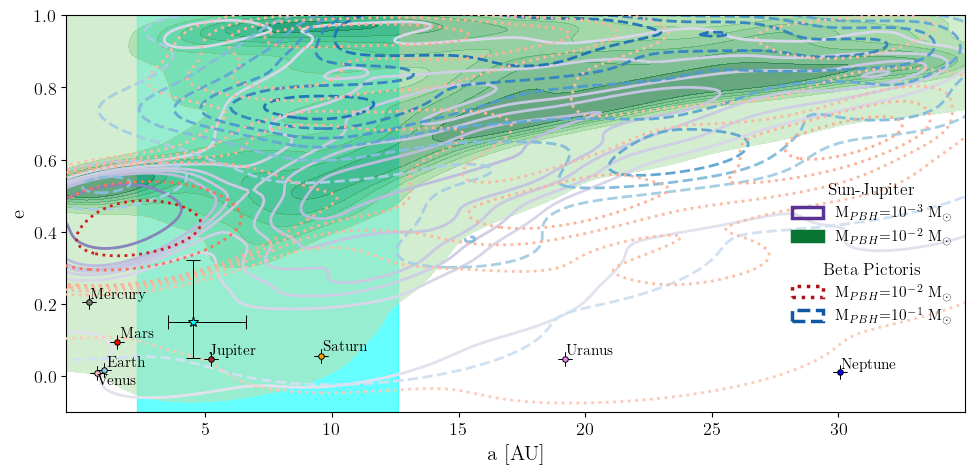

In [ ]:
fig2, ax2 = plt.subplots(figsize=(10, 5))
a_lim = 50
metric_masks = [[{
        "key": "termination_flag",
        "predicate": lambda a: "escape_B" not in a
    },{
        "key": "semi_major_axis_time_avg",
        "predicate": lambda a: a > 0 and a < a_lim  # Add a > 0
    },

    ], [{
        "key": "termination_flag",
        "predicate": lambda a: "escape_B" not  in a
    },{
        "key": "semi_major_axis_time_avg",
        "predicate": lambda a: a > 0 and a < a_lim  # Add a > 0
    },

    ]]
plotobj.plot_kde(
         metric_lists=[['semi_major_axis_time_avg', 'eccentricity_time_avg']],      
         metric_labels=[r'a [AU]', r'e'],
         scale=('linear', 'linear', 'linear'),
         ranges=[(-0.5, 35), (-0.1, 1)],
         cmaps = ['Purples','Greens', ],
         bw_adjust=0.7,
         thresh=0.0001,
         levels=8,
         alpha=[1.0, 0.6, 1],
         fill=[False,  True, False],
         metric_masks=metric_masks,
         analysis_key=[analysis_list_a[-1].name, analysis_list_a[-2].name],
         zorder=[2, 1, 1],
         linestyle=['-', '-', '-'],
         linewidth=[2.0, 0.0, 1.0],
         fig_size= (3.5, 3.5),
         ticks=[(5, 10, 15, 20, 25, 30), (0, 0.2, 0.4, 0.6, 0.8, 1)],
         fontsize=15,
         legend_position=(1.0, 0.5),
         legend_title='Sun-Jupiter',
         ax =ax2,
         save=False,
         save_as='sj_noexch_planets_a_e_kde_50au.png')

a_lim = 50
metric_masks = [[{
        "key": "termination_flag",
        "predicate": lambda a: "escape_B" not in a
    },{
        "key": "semi_major_axis_time_avg",
        "predicate": lambda a: a > 0 and a < a_lim  # Add a > 0
    },

    ], [{
        "key": "termination_flag",
        "predicate": lambda a: "escape_B" not in a
    },{
        "key": "semi_major_axis_time_avg",
        "predicate": lambda a: a > 0 and a < a_lim  # Add a > 0
    },

    ]]
plotobj_bp.plot_kde(
         metric_lists=[['semi_major_axis_time_avg', 'eccentricity_time_avg']],      
         metric_labels=[r'a [AU]', r'e'],
         scale=('linear', 'linear', 'linear'),
         ranges=[(-0.5, 35), (-0.1, 1)],
         cmaps = ['Reds','Blues'],
         bw_adjust=0.7,
         thresh=0.0001,
         levels=8,
         alpha=[1, 1, 1],
         fill=[False,  False, False],
         metric_masks=metric_masks,
         analysis_key=[betapic_analysis_list[-1].name, betapic_analysis_list[-2].name],
         zorder=[3, 2, 1],
         linestyle=[':', '--', '-'],
         linewidth=[2, 2, 1],
         fig_size= (3.5, 3.5),
         ticks=[(5, 10, 15, 20, 25, 30), (0, 0.2, 0.4, 0.6, 0.8, 1)],
         ax =ax2,
         fontsize=15,
         legend_position=(1.0, 0.3),
         legend_title='Beta Pictoris',
         extra_scatters=[
            {
                "x": merged_x,
                "y": merged_y,
                "x_err": merged_x_err,
                "y_err": merged_y_err,
                "marker": ['*']*len((sms_w_jmp_dps_microlensing['pl_orbsmax'].values)[~nan_ecc_mask]) + ['o']*len(solar_system_planets),
                "mfc": ['cyan']*len((sms_w_jmp_dps_microlensing['pl_orbsmax'].values)[~nan_ecc_mask]) + ['gray', 'pink', 'skyblue', 'red', 'brown', 'orange', 'violet', 'blue'],
                "edgecolors": 'black',
                "s": [8]*len((sms_w_jmp_dps_microlensing['pl_orbsmax'].values)[~nan_ecc_mask]) + [4]*len(solar_system_planets),
                # "mew": 0.1,
                "label": "Sun-like Stars with Jovian Planets",
                "text" : [None, 'Mercury', 'Venus', 'Earth', 'Mars', 'Jupiter', 'Saturn', 'Uranus', 'Neptune'],  # Add symbols for solar system planets),
                "text_color": 'black',  # ← Custom text color
                "linewidths": 0.7,
                "capsize": 5,
                "fontsize": 11,
                "xytext": [(2,1),(1, 1), (0,-10), (2,0), (2,1), (-1,1), (1,1), (1,1), (1,1)],  # Offset for text labels
            }
                ],

         extra_fills=[
        # For first dataset: shade uncertainty region
        
            {
                "x": np.array([min_orbsmax, max_orbsmax]),
                "color": "cyan",
                "alpha": 0.6,
                "label": "Microlensing Detection Range",
                "zorder": 0
            }
        ],
         save=True,
         save_as='combined_kde_noexchange.png')


## Additional Calculations

In [45]:
N_stars_at_8kpc = calc.star_number_at_ring(r=8)
print(f"Number of stars at 8 kpc: {N_stars_at_8kpc:.2e}")
N_stars_at_disc = calc.star_number_at_disc(r_in=2.2, r_out=8)
print(f"Number of stars in disc (2.2-8 kpc): {N_stars_at_disc:.2e}")
SJ_like_systems_at_8kpc = calc.star_number_at_ring(r=8, fraction=0.17)
print(f"Number of SJ-like systems at 8 kpc: {SJ_like_systems_at_8kpc:.2e}")
SJ_like_systems_at_disc = calc.star_number_at_disc(r_in=2.2, r_out=8, fraction=0.17)
print(f"Number of SJ-like systems in disc (2.2-8 kpc): {SJ_like_systems_at_disc:.2e}")
N_SJ_like_systems_at_8kpc = SJ_like_systems_at_8kpc * 2.1e-11
print(f"Number of SJ-like systems at 8 kpc: {N_SJ_like_systems_at_8kpc:.2e}")
N_SJ_like_systems_at_disc_min = SJ_like_systems_at_disc * 2.1e-11
print(f"Number of SJ-like systems in disc (2.2-8 kpc): {N_SJ_like_systems_at_disc_min:.2e}")
N_SJ_like_systems_at_disc_max = SJ_like_systems_at_disc * 3.28e-11
print(f"Number of SJ-like systems in disc (2.2-8 kpc): {N_SJ_like_systems_at_disc_max:.2e}")
N_stars_at_r = calc.star_number_at_r(r=8, dr=1)
print(f"Number of stars at 8 kpc (1 kpc ring): {N_stars_at_r:.2e}")
N_SJ_like_systems_at_r = calc.star_number_at_r(r=8, dr=1, fraction=0.17)
print(f"Number of SJ-like systems at 8 kpc (1 kpc ring): {N_SJ_like_systems_at_r:.2e}")
N_stars_at_bulge = calc.star_number_at_r(r=1.2, dr=2)
print(f"Number of stars in bulge (0-2.2 kpc): {N_stars_at_bulge:.2e}")
N_SJ_like_systems_at_bulge = calc.star_number_at_r(r=1.2, dr=2, fraction=0.17)
print(f"Number of SJ-like systems in bulge (0-2.2 kpc): {N_SJ_like_systems_at_bulge:.2e}")

Number of stars at 8 kpc: 2.63e+07
Number of stars in disc (2.2-8 kpc): 6.20e+08
Number of SJ-like systems at 8 kpc: 4.47e+06
Number of SJ-like systems in disc (2.2-8 kpc): 1.05e+08
Number of SJ-like systems at 8 kpc: 9.40e-05
Number of SJ-like systems in disc (2.2-8 kpc): 2.21e-03
Number of SJ-like systems in disc (2.2-8 kpc): 3.45e-03
Number of stars at 8 kpc (1 kpc ring): 2.03e+09
Number of SJ-like systems at 8 kpc (1 kpc ring): 3.45e+08
Number of stars in bulge (0-2.2 kpc): 1.68e+10
Number of SJ-like systems in bulge (0-2.2 kpc): 2.86e+09


In [117]:
M_and_vel_bary_at_8kpc = calc.baryonic_mass_and_velocity_milkyway(r=8)
M_and_vel_bary_at_20kpc = calc.baryonic_mass_and_velocity_milkyway(r=20)
M_and_vel_bary_at_01kpc = calc.baryonic_mass_and_velocity_milkyway(r=0.01)
M_and_vel_bary_at_2d2kpc = calc.baryonic_mass_and_velocity_milkyway(r=2.2)
M_dm_at_2d2kpc = calc.dark_matter_mass_and_velocity_milkyway(r=2.2)
M_and_vel_bary_at_2d2to8kpc = calc.baryonic_mass_and_velocity_milkyway(r=8.5, r_in=7.5)
print(f"Baryonic mass at 8 kpc: {M_and_vel_bary_at_8kpc[0]:.2e} Msun")
print(f"Baryonic velocity at 8 kpc: {M_and_vel_bary_at_8kpc[1]:.2f} km/s")
print(f"Baryonic mass at 20 kpc: {M_and_vel_bary_at_20kpc[0]:.2e} Msun")
print(f"Baryonic velocity at 20 kpc: {M_and_vel_bary_at_20kpc[1]:.2f} km/s")
print(f"Baryonic mass at 0.01 kpc: {M_and_vel_bary_at_01kpc[0]:.2e} Msun")
print(f"Baryonic velocity at 0.01 kpc: {M_and_vel_bary_at_01kpc[1]:.2f} km/s")
print(f"Baryonic mass at 2.2 kpc: {M_and_vel_bary_at_2d2kpc[0]:.2e} Msun")
print(f"Baryonic velocity at 2.2 kpc: {M_and_vel_bary_at_2d2kpc[1]:.2f} km/s")
print(f"Baryonic mass at 2.2-8 kpc: {M_and_vel_bary_at_2d2to8kpc[0]:.2e} Msun")
print(f"Baryonic velocity at 2.2-8 kpc: {M_and_vel_bary_at_2d2to8kpc[1]:.2f} km/s")

M_dm_at_8kpc = calc.dark_matter_mass_and_velocity_milkyway(r=8)
print(f"DM mass at 8 kpc: {M_dm_at_8kpc[0]:.2e} Msun")
print(f"DM velocity at 8 kpc: {M_dm_at_8kpc[1]:.2f} km/s")
print(f"DM mass at 2.2 kpc: {M_dm_at_2d2kpc[0]:.2e} Msun")
print(f"DM velocity at 2.2 kpc: {M_dm_at_2d2kpc[1]:.2f} km/s")
total_mass_at_8kpc = M_and_vel_bary_at_8kpc[0] + M_dm_at_8kpc[0]
print(f"Total mass at 8 kpc: {total_mass_at_8kpc:.2e} Msun")
v_circ_at_8kpc = np.sqrt(M_and_vel_bary_at_8kpc[1]**2 + M_dm_at_8kpc[1]**2)
print(f"Circular velocity at 8 kpc: {v_circ_at_8kpc:.2f} km/s")
total_mass_at2d2kpc = M_and_vel_bary_at_2d2kpc[0] + M_dm_at_2d2kpc[0]
print(f"Total mass at 2.2 kpc: {total_mass_at2d2kpc:.2e} Msun")
v_circ_at_2d2kpc = np.sqrt(M_and_vel_bary_at_2d2kpc[1]**2 + M_dm_at_2d2kpc[1]**2)
print(f"Circular velocity at 2.2 kpc: {v_circ_at_2d2kpc:.2f} km/s")


Baryonic mass at 8 kpc: 4.60e+10 Msun
Baryonic velocity at 8 kpc: 174.47 km/s
Baryonic mass at 20 kpc: 5.47e+10 Msun
Baryonic velocity at 20 kpc: 111.98 km/s
Baryonic mass at 0.01 kpc: 3.38e+06 Msun
Baryonic velocity at 0.01 kpc: 36.23 km/s
Baryonic mass at 2.2 kpc: 1.80e+10 Msun
Baryonic velocity at 2.2 kpc: 188.67 km/s
Baryonic mass at 2.2-8 kpc: 2.23e+09 Msun
Baryonic velocity at 2.2-8 kpc: 170.83 km/s
DM mass at 8 kpc: 4.45e+10 Msun
DM velocity at 8 kpc: 154.72 km/s
DM mass at 2.2 kpc: 2.43e+09 Msun
DM velocity at 2.2 kpc: 68.93 km/s
Total mass at 8 kpc: 9.05e+10 Msun
Circular velocity at 8 kpc: 233.20 km/s
Total mass at 2.2 kpc: 2.05e+10 Msun
Circular velocity at 2.2 kpc: 200.87 km/s


Example: Milky Way
At the Orbit of the Sun:
R=8 kpc, Vrot=220 km/sec
Gives: M = 9.0x1010 Msun inside R=8 kpc
https://www.astronomy.ohio-state.edu/thompson.1847/1144/Lecture25.html

In [37]:
occurence_rate = integrated_results[0]["N_eq_full_stars_integrated"]/ integrated_results[0]['N_stars_total_integrated']
print(f"Occurrence rate: {occurence_rate:.2e}")
# occurence_rate = integrated_results[0]['N_eq_full_alike_integrated'] / integrated_results[0]['N_stars_total_integrated']
# print(f"Occurrence rate (alike): {occurence_rate:.2e}")
roman_stars = 59e6
det_prob = occurence_rate * roman_stars
print(f"Expected number of captures in Roman survey: {det_prob}")

Occurrence rate: 1.79e-10
Expected number of captures in Roman survey: 0.010564112791593895


Circular velocity at 8 kpc: 233.19530568027946
f(v) for PBHs at v_inf: [8.43620276e-09 3.19851606e-05 1.25614461e-04 2.80138981e-04
 4.94310495e-04 7.66402496e-04 1.09422758e-03 1.47515936e-03
 1.90615874e-03 2.38380404e-03 2.90432484e-03 3.46363892e-03
 4.05739193e-03 4.68099936e-03 5.32969021e-03 5.99855191e-03
 6.68257595e-03 7.37670370e-03 8.07587187e-03 8.77505722e-03
 9.46931985e-03 1.01538448e-02 1.08239813e-02 1.14752800e-02
 1.21035262e-02 1.27047710e-02 1.32753586e-02 1.38119492e-02
 1.43115394e-02 1.47714777e-02 1.51894762e-02 1.55636190e-02
 1.58923654e-02 1.61745510e-02 1.64093833e-02 1.65964356e-02
 1.67356361e-02 1.68272552e-02 1.68718890e-02 1.68704414e-02
 1.68241030e-02 1.67343293e-02 1.66028164e-02 1.64314760e-02
 1.62224098e-02 1.59778830e-02 1.57002977e-02 1.53921668e-02
 1.50560872e-02 1.46947154e-02 1.43107419e-02 1.39068686e-02
 1.34857862e-02 1.30501535e-02 1.26025781e-02 1.21455991e-02
 1.16816714e-02 1.12131513e-02 1.07422847e-02 1.02711968e-02
 9.80188338e-0

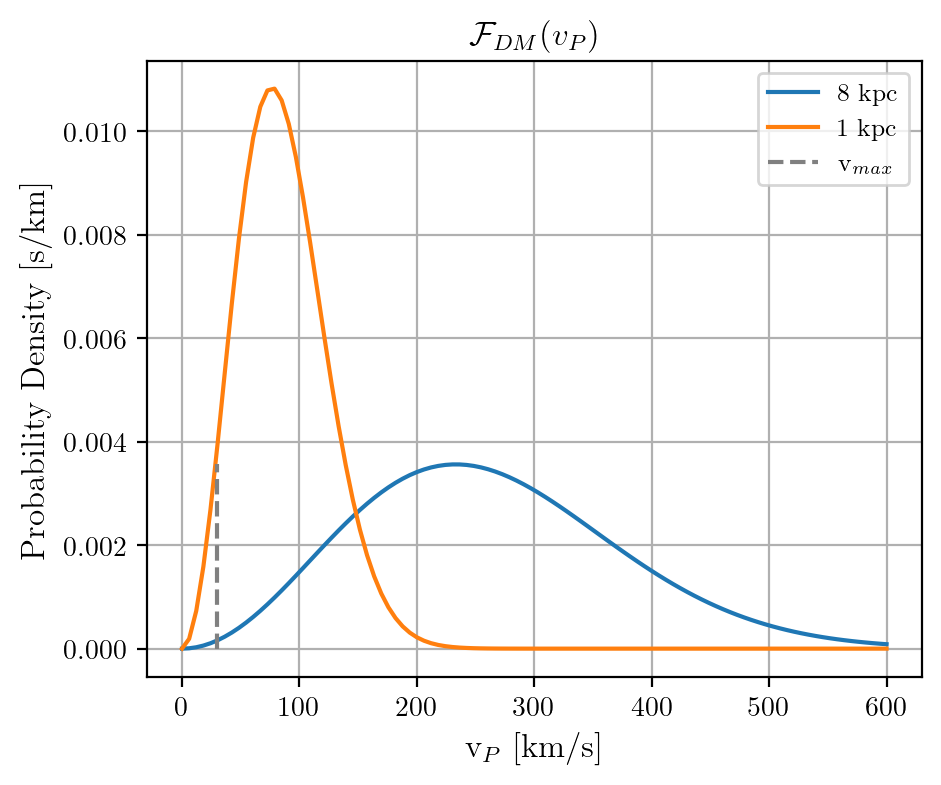

In [50]:
Vc_at8kpc = calc.circular_velocity_milkyway(8)

print(f"Circular velocity at 8 kpc: {Vc_at8kpc}")
vinf = np.linspace(0.1, 600, 100) 
# vinf_au_yr = vinf.to(u.au/u.yr)
# print(f"v_inf = {vinf_au_yr:.2e} AU/yr")
# fpbh_v_local = calc.v_pbh_pdf_local(vinf_au_yr.value)
# print(f"f(v) for PBHs at v_inf: {fpbh_v_local:.2e} yr/AU")
fpbh_dm_local = calc.v_pbh_pdf(vinf, 8)
print(f"f(v) for PBHs at v_inf: {fpbh_dm_local}")
fpbh_dm_local = fpbh_dm_local.to(u.s/u.km).value
fpbh_dm_old = calc.v_pbh_pdf_old(vinf, 8, 220*u.km/u.s)
fpbh_dm_old = fpbh_dm_old.to(u.s/u.km).value 
# fpbh_dm_local2 = calc.v_pbh_pdf_local(vinf, Vc_at8kpc/np.sqrt(2))
# print(f"f(v) for PBHs at v_inf: {fpbh_dm_local:.2e} Msun/(AU^3 yr)")
# fpbh_dm_local2 = fpbh_dm_local2.to(u.s/u.km).value * 1e3
# print(f"Difference between f(v) with Vc and Vc/sqrt(2): {diff}")
Vc_at1kpc = calc.circular_velocity_milkyway(1)
print(f"Circular velocity at 1 kpc: {Vc_at1kpc:.2f}")
fphb_dm_1kpc = calc.v_pbh_pdf(vinf, Vc_at1kpc)
fphb_dm_1kpc = fphb_dm_1kpc.to(u.s/u.km).value 
# fpbh_dm_1kpc2 = calc.v_pbh_pdf_local(vinf, Vc_at1kpc/np.sqrt(2))
# fpbh_dm_1kpc2 = fpbh_dm_1kpc2.to(u.s/u.km).value * 1e3
# diff = np.abs(fpbh_dm_1kpc2 - fpbh_dm_local2)

plt.figure(figsize=(5, 4))
plt.plot(vinf, fpbh_dm_local, label='8 kpc')
# plt.plot(vinf, fpbh_dm_local2, label='f(v) for PBHs at v_inf (Vc/sqrt(2))')
plt.plot(vinf, fphb_dm_1kpc, label='1 kpc')
plt.vlines(30, ymin=0, ymax=np.max(fpbh_dm_local), colors='gray', linestyles='dashed', label=r'v$_{max}$')
# plt.plot(vinf, fpbh_dm_1kpc2, label='f(v) for PBHs at v_inf (1 kpc, Vc/sqrt(2))')
# plt.plot(vinf, fpbh_dm_old, label='f(v) for PBHs at 8 kpc (old)', linestyle='dashed')
plt.xlabel(r'v$_{P}$ [km/s]')
plt.ylabel('Probability Density [s/km]')
plt.title(r'$\mathcal{F}_{DM}(v_{P})$')
plt.legend()
plt.savefig('f_v_pbh_dm.png', bbox_inches='tight')
plt.show()

# plt.plot(vinf, diff, label='Difference between f(v) with Vc and Vc/sqrt(2)')
# plt.xlabel('v_inf [km/s]')
# plt.ylabel('Difference')
# plt.title('Difference in Velocity Distribution of PBHs at Infinity')
# plt.legend()
# plt.grid()
# plt.show()